# AI Data Centre Buildout: Quantitative Analysis

An end-to-end study of a thematic equity portfolio built around the physical infrastructure behind AI compute: the colocation REITs that house the racks, the firms that power and cool them, and the networking hardware that connects them.

## What this notebook is, and what it is not

It is the exploratory half of a two-part project. This notebook builds the universe, decomposes returns into known risk factors, constructs portfolios under several objectives, and projects forward. It is where the ideas are generated.

It is not the validation. Most of what is estimated here is estimated in sample, and several steps contain biases that I have chosen to document in place rather than quietly remove. The companion notebook, `unified_analysis.ipynb`, re-runs the core of this work under a temporal train/test split with an embargo, walk-forward estimation, and formal multiple-testing corrections. The two notebooks disagree, and that disagreement is the most informative output of the project.

I have kept the biased version visible on purpose. A thematic portfolio that looks excellent in sample and merely acceptable out of sample is the normal outcome, and seeing both is more useful than seeing only the second.

## Structure

1. Data acquisition and the investment universe
2. Exploratory analysis: distributions, correlation structure, rolling estimates
3. Fama-French five-factor decomposition
4. Portfolio optimisation: tangency, constrained, minimum variance
5. Black-Litterman with thematic views
6. Walk-forward backtesting
7. Risk analysis: VaR, CVaR, marginal contributions, tail dependence
8. Monte Carlo projection
9. Summary

Dependencies: `yfinance pandas numpy scipy matplotlib seaborn statsmodels scikit-learn`


## 0. Setup and configuration

All parameters that could change a result are declared here rather than inline. The sample is specified from January 2019, early enough to predate the thematic repricing. In practice it starts in late October 2020, because one thematic ETF lists late and the loader drops incomplete rows; section 1.2 sets out why.

One consequence of that window deserves stating up front: the effective sample contains the 2021 liquidity boom, the 2022 rate shock and the 2023 onward AI repricing, but not the 2020 crash, and no sustained bear market in the theme itself. Every expected return estimated from this sample inherits that.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from datetime import datetime
from scipy.optimize import minimize
from scipy.stats import norm, t as t_dist, rankdata, jarque_bera
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.figsize': (14, 7), 'figure.dpi': 120, 'font.size': 11,
    'axes.titlesize': 14, 'axes.labelsize': 12, 'figure.facecolor': 'white',
})

COLORS = {
    'navy': '#1B2A4A', 'blue': '#3B7DD8', 'gold': '#C8A951',
    'teal': '#2CA58D', 'red': '#D64045', 'gray': '#888888',
    'green': '#4CAF50', 'purple': '#7B68EE', 'orange': '#FF8C00',
}
PALETTE = list(COLORS.values())

# ── Risk-free rate (annualized, approximate 10Y UST) ──
RF_ANNUAL = 0.045
RF_MONTHLY = (1 + RF_ANNUAL) ** (1/12) - 1

print("All imports successful. Setup complete.")


All imports successful. Setup complete.


## 1. Data acquisition

### 1.1 Investment universe

The thesis is that AI compute demand is a physical-infrastructure story before it is a semiconductor story. Model training needs buildings, power, cooling and fibre, and those are supplied by companies whose revenue is contracted and whose capacity takes years to build. The universe is constructed as four clusters along that supply chain.

| Cluster | Tickers | Economic role |
|---|---|---|
| Data centre REITs | EQIX, DLR, AMT, CCI, IRM | Own the buildings and lease capacity under long-dated contracts |
| Asia operators | GDS, VNET | Same business model, different regulatory and currency regime |
| Infrastructure | VRT, ANET, CSCO, MRVL, SBGSY, ETN, JCI, HON, GNRC, CAT | Power distribution, thermal management, networking |
| Thematic ETFs | DTCR, SRVR | Passive exposure, included as a benchmark for the stock selection |
| Benchmark | SPY | Broad market |

Including the thematic ETFs alongside the individual names is deliberate. If the optimised portfolio cannot beat DTCR and SRVR, then the stock-level work added nothing that could not have been bought for a few basis points, and that is worth knowing.

The universe is defined here, before any model is run, and is not revisited. Selecting names after seeing which ones performed well is the most common way backtests acquire a bias they cannot be corrected for.


In [2]:
# ══════════════════════════════════════════════════════════════
# TICKER UNIVERSE DEFINITION
# ══════════════════════════════════════════════════════════════

CLUSTERS = {
    'REIT':           ['EQIX', 'DLR', 'AMT', 'CCI', 'IRM'],
    'Asia':           ['GDS', 'VNET'],
    'Infrastructure': ['VRT', 'ANET', 'CSCO', 'MRVL', 'SBGSY', 'ETN', 'JCI', 'HON', 'GNRC', 'CAT'],
    'ETF':            ['DTCR', 'SRVR'],
}

ALL_TICKERS = [t for tickers in CLUSTERS.values() for t in tickers]
BENCHMARK = 'SPY'
FACTOR_ETFS = ['IWM', 'IWD', 'IWF']  # For FF factor proxies

TICKER_CLUSTER = {}
for cluster, tickers in CLUSTERS.items():
    for t in tickers:
        TICKER_CLUSTER[t] = cluster

START_DATE = '2019-01-01'
END_DATE   = '2026-03-01'

print(f"Universe: {len(ALL_TICKERS)} assets across {len(CLUSTERS)} clusters")
print(f"Period:   {START_DATE} -> {END_DATE}")


Universe: 19 assets across 4 clusters
Period:   2019-01-01 -> 2026-03-01


### 1.2 Price data

I use split- and dividend-adjusted closes, which makes the series a total return. For a portfolio with five REITs in it this is not a detail. REITs distribute the bulk of taxable income by statute, so a large share of their total return arrives as dividends; a price-return series would understate them by several percentage points a year while leaving the growth names roughly unaffected, biasing every subsequent comparison against the income side of the portfolio.

Where a snapshot CSV is present, it is used in preference to a live download, so the notebook reproduces the same numbers on every run.

### A truncation worth knowing about

The loader drops any row with a missing price in any column. DTCR, one of the two thematic ETFs, only lists from October 2020, so that single series moves the start of the entire sample forward by roughly 22 months, from January 2019 to late 2020. Everything downstream inherits the shorter window, and in particular **the sample contains no part of the COVID crash**. The coverage diagnostic in the next cell prints the truncation explicitly.

I have kept the behaviour rather than changed it, because changing the sample changes every result in the notebook and the comparison with earlier runs would be lost. The better design treats the ETFs as benchmarks evaluated on their own available history rather than as optimisation inputs that constrain everyone else's.


In [3]:
# ══════════════════════════════════════════════════════════════
# DATA LOADING
# ══════════════════════════════════════════════════════════════
#
# Resolution order: the frozen snapshot written by fetch_data.py, then a live
# yfinance download. If both fail, this cell raises.
#
# An earlier version fell back to SYNTHETIC prices "calibrated to 2019-2024"
# when the download failed. That fallback has been removed deliberately. A
# notebook that silently substitutes simulated data produces charts, tables
# and a printed summary that look exactly like real results, and one copy of
# this notebook was in fact executed that way behind a corporate proxy with
# nothing in its markdown to say so. Failing loudly is the correct behaviour.

import os

download_tickers = ALL_TICKERS + [BENCHMARK] + FACTOR_ETFS
SNAPSHOT = os.path.join('data_cache', 'prices_daily.csv')

if os.path.exists(SNAPSHOT):
    raw_prices = pd.read_csv(SNAPSHOT, index_col=0, parse_dates=True)
    raw_prices = raw_prices.loc[START_DATE:END_DATE]
    DATA_SOURCE = 'snapshot'
else:
    import yfinance as yf
    print("No snapshot found, downloading from Yahoo Finance...")
    raw_prices = yf.download(download_tickers, start=START_DATE, end=END_DATE,
                             auto_adjust=True, progress=False)['Close']
    DATA_SOURCE = 'yfinance'

missing = [t for t in download_tickers if t not in raw_prices.columns
           or raw_prices[t].notna().sum() == 0]
if missing:
    print(f"Missing from source: {missing}")

prices = raw_prices[[t for t in download_tickers if t not in missing]].copy()

# Coverage: report late starters BEFORE the row-wise dropna below, because
# that dropna truncates the whole universe to the latest first-valid date.
first_valid = prices.apply(lambda s: s.first_valid_index())
latest = first_valid.max()
late = first_valid[first_valid > pd.Timestamp(START_DATE) + pd.Timedelta(days=30)]
if len(late):
    print("Series starting materially after START_DATE:")
    for t, d in late.sort_values().items():
        print(f"  {t:<6} first valid {d.date()}")
    print(f"=> the row-wise dropna below truncates the sample to start {latest.date()}")

prices = prices.ffill(limit=5).dropna()

if prices.shape[0] < 100 or prices.shape[1] < 5:
    raise RuntimeError(
        f"Insufficient price data {prices.shape}. Run fetch_data.py from a machine "
        f"with internet access to create {SNAPSHOT}. This notebook will not "
        f"substitute simulated data."
    )

# ── Update active ticker lists ──
ACTIVE_TICKERS = [t for t in ALL_TICKERS if t in prices.columns]
for cluster in CLUSTERS:
    CLUSTERS[cluster] = [t for t in CLUSTERS[cluster] if t in prices.columns]

print(f"\nLoaded {prices.shape[1]} tickers, {prices.shape[0]} trading days "
      f"({prices.index[0].date()} to {prices.index[-1].date()})")
print(f"Active tickers: {len(ACTIVE_TICKERS)}")
print(f"Data source: {DATA_SOURCE}")
prices.tail(3)

Series starting materially after START_DATE:
  DTCR   first valid 2020-10-29
=> the row-wise dropna below truncates the sample to start 2020-10-29

Loaded 23 tickers, 1338 trading days (2020-10-29 to 2026-02-27)
Active tickers: 19
Data source: snapshot


,EQIX,DLR,AMT,CCI,IRM,GDS,VNET,VRT,ANET,CSCO,...,JCI,HON,GNRC,CAT,DTCR,SRVR,SPY,IWM,IWD,IWF
Date,,,,,,,,,,,,,,,,,,,,,
2026-02-25,951.247559,175.987305,177.052155,82.793861,109.274094,44.990002,11.79,262.008881,132.889999,78.097534,...,143.247452,250.623169,236.580002,763.736450,25.636070,32.494194,687.778015,262.797211,222.668564,114.320595
2026-02-26,938.868225,172.831909,179.506897,83.140282,106.898567,41.790001,11.39,259.050934,130.250000,77.090721,...,142.186661,249.257248,234.350006,750.107727,25.317238,32.290501,683.957825,264.197723,223.004990,113.235985
2026-02-27,964.854858,173.645248,186.153168,86.161812,105.901436,41.310001,10.78,254.713898,133.500000,78.433136,...,143.059082,253.312927,225.369995,740.045654,25.466690,32.634842,680.673462,259.648621,223.143509,112.248619


### 1.3 Returns

Daily returns are used for the risk work and monthly returns for the optimisation and factor analysis. The split is not arbitrary.

Daily data gives 1,338 observations over the effective sample, which is what tail estimation and correlation dynamics need. But daily returns are also noisier, and more importantly, mean estimates do not improve with sampling frequency. Merton (1980) makes the point precisely: the standard error of an estimated mean depends on the calendar length of the sample, not on how finely it is sliced, while the standard error of an estimated variance does fall with frequency. Sampling daily buys better covariance estimates and does nothing at all for expected returns.

That asymmetry is the central estimation problem in everything that follows. With a little over five years of data the standard error on an annual mean return is about 13 percentage points for a name running 30% volatility. The optimiser in section 4 will treat those estimates as if they were known, which is exactly why its output needs the constraints and the scepticism applied later.

In [4]:
# ══════════════════════════════════════════════════════════════
# RETURN COMPUTATION
# ══════════════════════════════════════════════════════════════

daily_returns = prices.pct_change().dropna()
monthly_prices = prices.resample('ME').last()
monthly_returns = monthly_prices.pct_change().dropna()

# ── Annualized summary statistics ──
ann_ret = monthly_returns[ACTIVE_TICKERS].mean() * 12
ann_vol = monthly_returns[ACTIVE_TICKERS].std() * np.sqrt(12)
ann_sharpe = (ann_ret - RF_ANNUAL) / ann_vol

summary = pd.DataFrame({
    'Ann. Return':    ann_ret,
    'Ann. Volatility': ann_vol,
    'Sharpe Ratio':   ann_sharpe,
    'Skewness':       monthly_returns[ACTIVE_TICKERS].skew(),
    'Excess Kurtosis':monthly_returns[ACTIVE_TICKERS].kurt(),
    'Cluster':        [TICKER_CLUSTER.get(t, 'N/A') for t in ACTIVE_TICKERS],
}).sort_values('Sharpe Ratio', ascending=False)

print("Annualized Statistics (Monthly Returns)\n")
display_df = summary.copy()
display_df['Ann. Return'] = display_df['Ann. Return'].map('{:.2%}'.format)
display_df['Ann. Volatility'] = display_df['Ann. Volatility'].map('{:.2%}'.format)
display_df['Sharpe Ratio'] = display_df['Sharpe Ratio'].map('{:.2f}'.format)
display_df['Skewness'] = display_df['Skewness'].map('{:.2f}'.format)
display_df['Excess Kurtosis'] = display_df['Excess Kurtosis'].map('{:.2f}'.format)
print(display_df.to_string())


Annualized Statistics (Monthly Returns)

      Ann. Return Ann. Volatility Sharpe Ratio Skewness Excess Kurtosis         Cluster
ANET       51.58%          38.64%         1.22    -0.10           -0.27  Infrastructure
IRM        35.39%          28.33%         1.09    -0.38           -0.43            REIT
VRT        67.69%          59.17%         1.07     0.26            0.49  Infrastructure
CAT        36.82%          34.01%         0.95     0.37            0.16  Infrastructure
ETN        29.57%          26.75%         0.94     0.02           -0.86  Infrastructure
JCI        29.25%          28.91%         0.86     0.01           -0.52  Infrastructure
SBGSY      24.15%          27.80%         0.71     0.06           -0.07  Infrastructure
CSCO       20.37%          22.65%         0.70     0.24            0.36  Infrastructure
DTCR       14.54%          21.29%         0.47    -0.08            0.48             ETF
MRVL       27.73%          51.32%         0.45     0.35            0.77  Infras

## 2. Exploratory analysis

### 2.1 Cumulative return paths

Before fitting anything, the point of this section is to establish what the data looks like and, specifically, whether the assumptions the optimiser will make are defensible. They mostly are not, and documenting that here is what justifies the constrained and shrunk variants later.

The cumulative paths show the theme's dispersion directly. A spread of this width across names that are supposedly exposed to one driver is the first indication that "the AI infrastructure trade" is not a single factor, and that the correlation structure is doing more work than the narrative suggests.


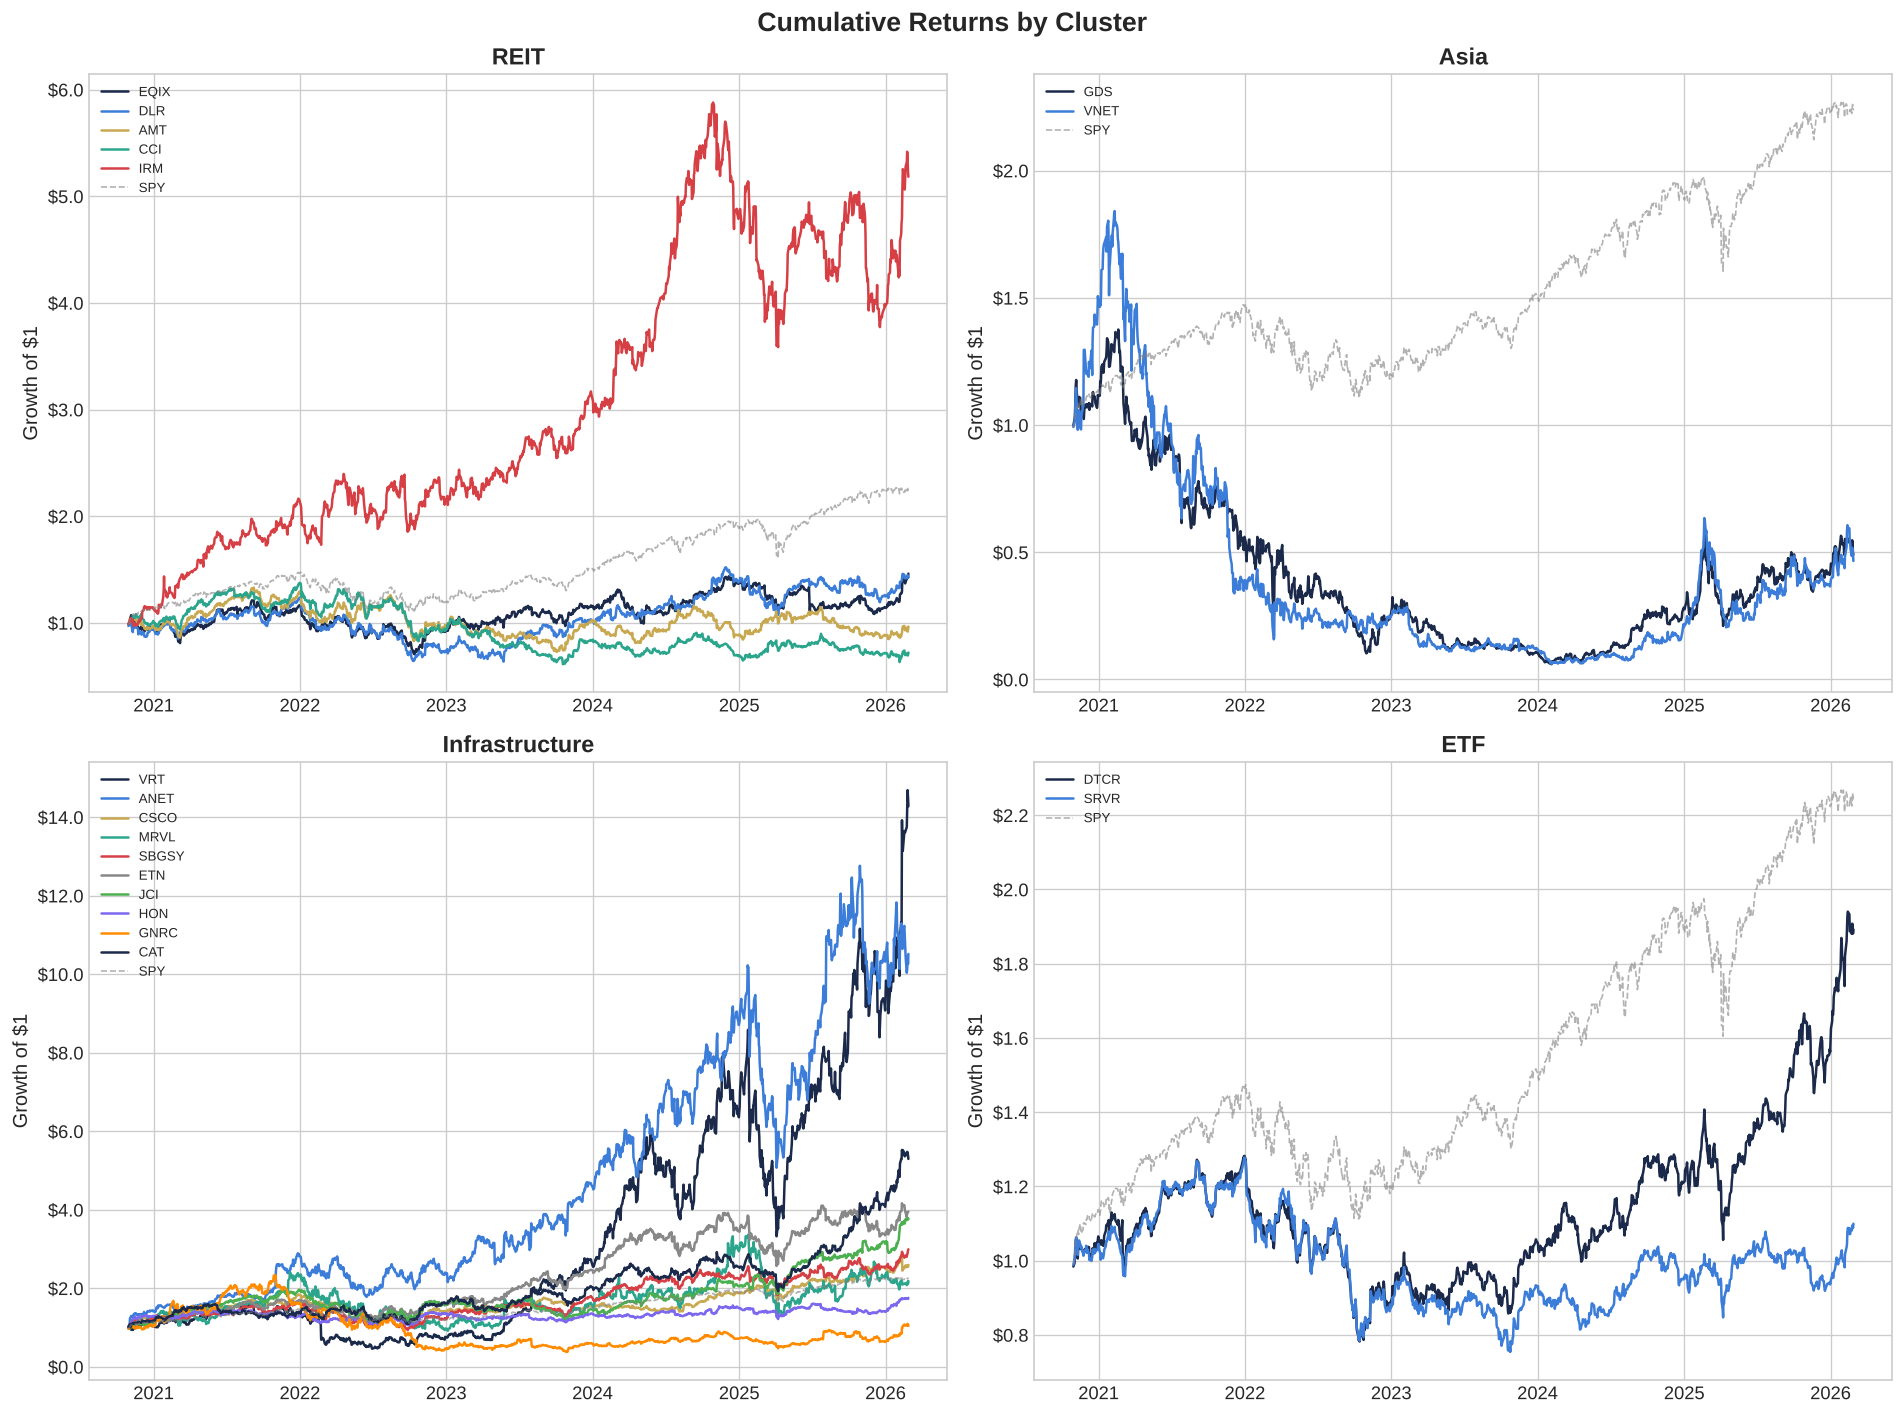

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Cumulative Returns by Cluster', fontsize=16, fontweight='bold')

for ax, (cluster, tickers) in zip(axes.flat, CLUSTERS.items()):
    if not tickers:
        ax.set_visible(False)
        continue
    cum = (1 + daily_returns[tickers]).cumprod()
    for i, t in enumerate(tickers):
        ax.plot(cum.index, cum[t], label=t, linewidth=1.5, color=PALETTE[i % len(PALETTE)])
    
    if BENCHMARK in daily_returns.columns:
        spy_cum = (1 + daily_returns[BENCHMARK]).cumprod()
        ax.plot(spy_cum.index, spy_cum, label='SPY', linewidth=1, color='gray', ls='--', alpha=0.6)
    
    ax.set_title(f'{cluster}', fontweight='bold')
    ax.set_ylabel('Growth of $1')
    ax.legend(loc='upper left', fontsize=8)
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('$%.1f'))

plt.tight_layout()
plt.show()


### 2.2 Correlation structure

The correlation matrix is the input the optimiser is most sensitive to and the one estimated with the least reliability.

With $N$ assets there are $N(N-1)/2$ pairwise correlations to estimate. For the 19-name universe that is 171 parameters estimated from 64 monthly observations. The sample covariance matrix is not merely noisy in that regime, it is close to singular, and Markowitz optimisation inverts it. Inverting a near-singular matrix amplifies precisely the directions in which the estimate is least reliable, which is the mechanism behind the well-documented tendency of mean-variance optimisers to produce extreme and unstable weights. Michaud (1989) called it an error-maximising procedure, and that is not a figure of speech: the optimiser systematically overweights assets whose returns were overestimated and whose covariances were underestimated.

Two responses appear later. The weight cap in section 4 constrains the symptom. Ledoit-Wolf shrinkage in the companion notebook treats the cause by pulling the sample matrix toward a structured target, trading a small bias for a large reduction in variance.

The cluster structure visible in the heatmap is also what makes the diversification claim testable. If the REITs, the power names and the networking names were genuinely distinct exposures, the matrix would be block-diagonal. The degree to which it is not is the degree to which this is one bet wearing four hats.

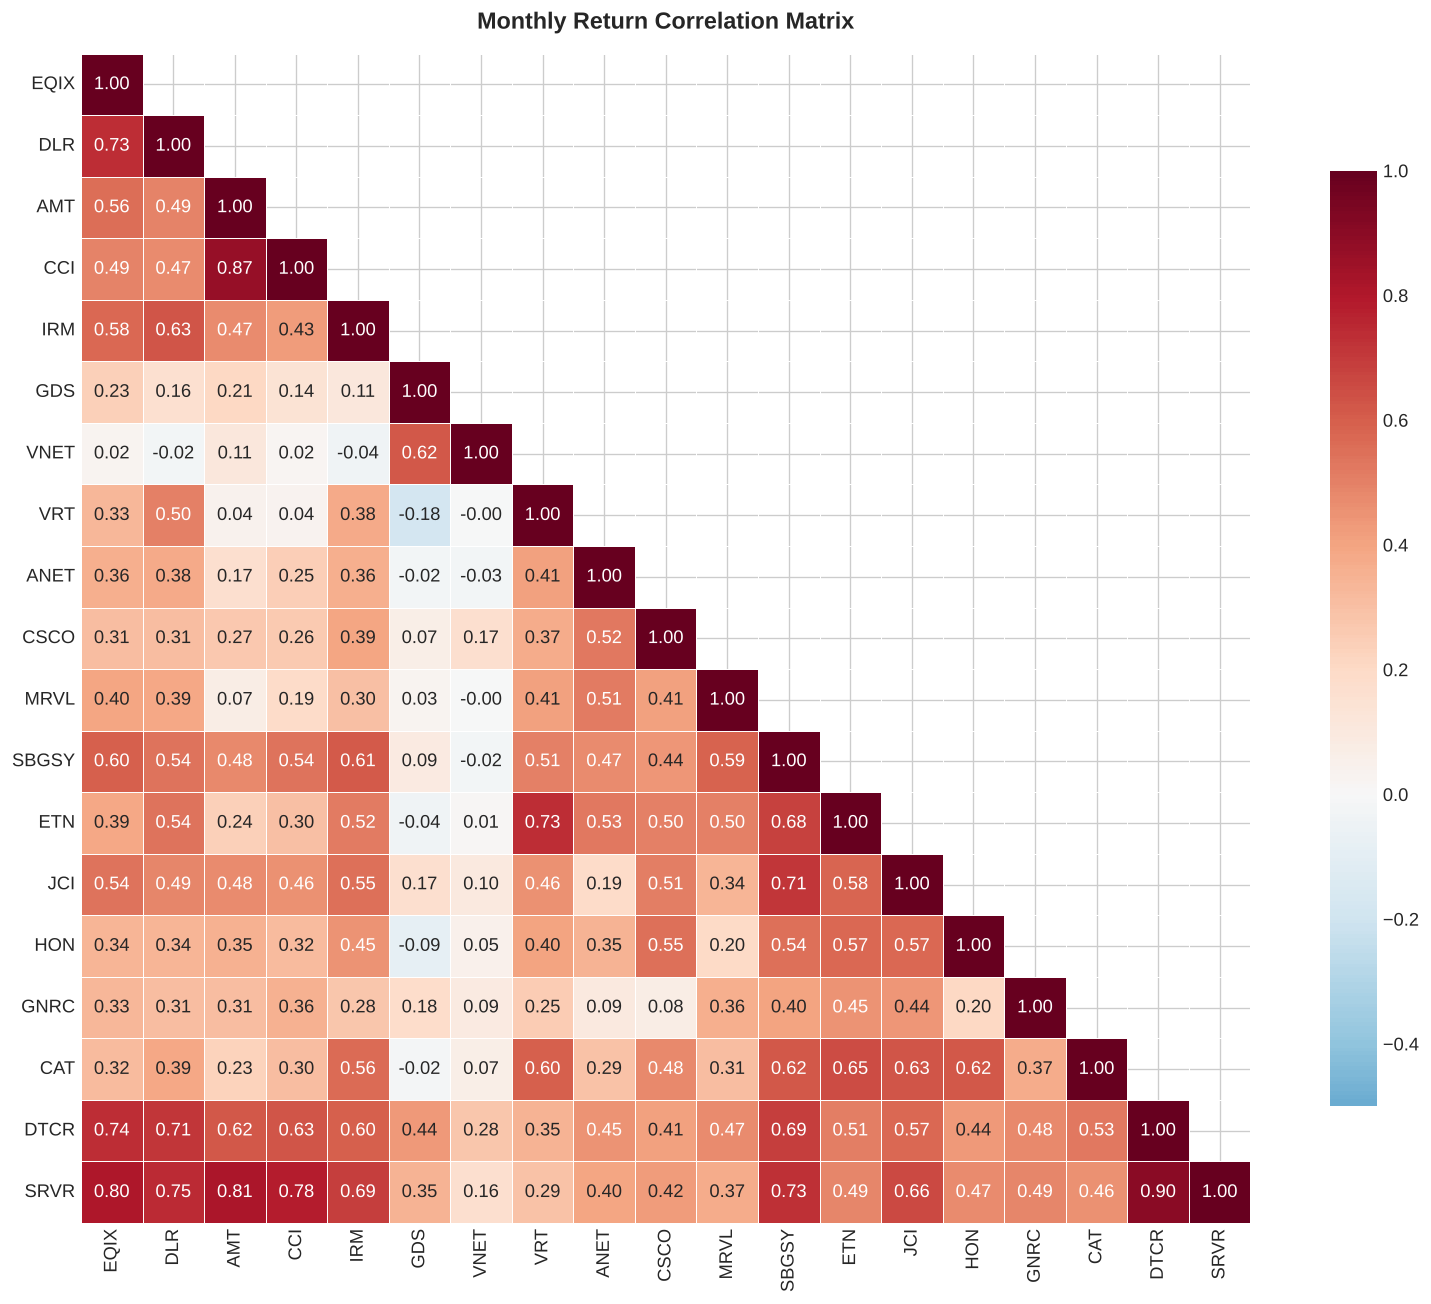


Highest correlated pairs:
DTCR  SRVR   0.897
AMT   CCI    0.871
      SRVR   0.814
EQIX  SRVR   0.802
CCI   SRVR   0.781
DLR   SRVR   0.747
EQIX  DTCR   0.741
      DLR    0.735

Lowest correlated pairs:
GDS   VRT    -0.179
      HON    -0.086
      ETN    -0.039
IRM   VNET   -0.038
VNET  ANET   -0.029


In [6]:
corr = monthly_returns[ACTIVE_TICKERS].corr()

fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-0.5, vmax=1.0, square=True, linewidths=0.5,
            cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Monthly Return Correlation Matrix', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# Key pairs
corr_pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print("\nHighest correlated pairs:")
print(corr_pairs.nlargest(8).to_string(float_format='{:.3f}'.format))
print("\nLowest correlated pairs:")
print(corr_pairs.nsmallest(5).to_string(float_format='{:.3f}'.format))


### 2.3 Rolling volatility and beta

Both are plotted over a moving window because both move, and that movement is the problem.

The optimisation in section 4 estimates a single covariance matrix over a single window and treats it as the truth. If realised volatility doubles between regimes, which it does here around 2020 and again through 2022, then any fixed-window estimate is a weighted average of states the portfolio was never simultaneously in. The resulting weights are optimal for an average market that does not exist.

Rolling beta against SPY makes a related point about the thesis itself. If beta drifts upward through the sample, the portfolio's apparent outperformance is partly compensation for taking more market risk, not evidence of a thematic edge. Section 3 is where that gets separated properly.


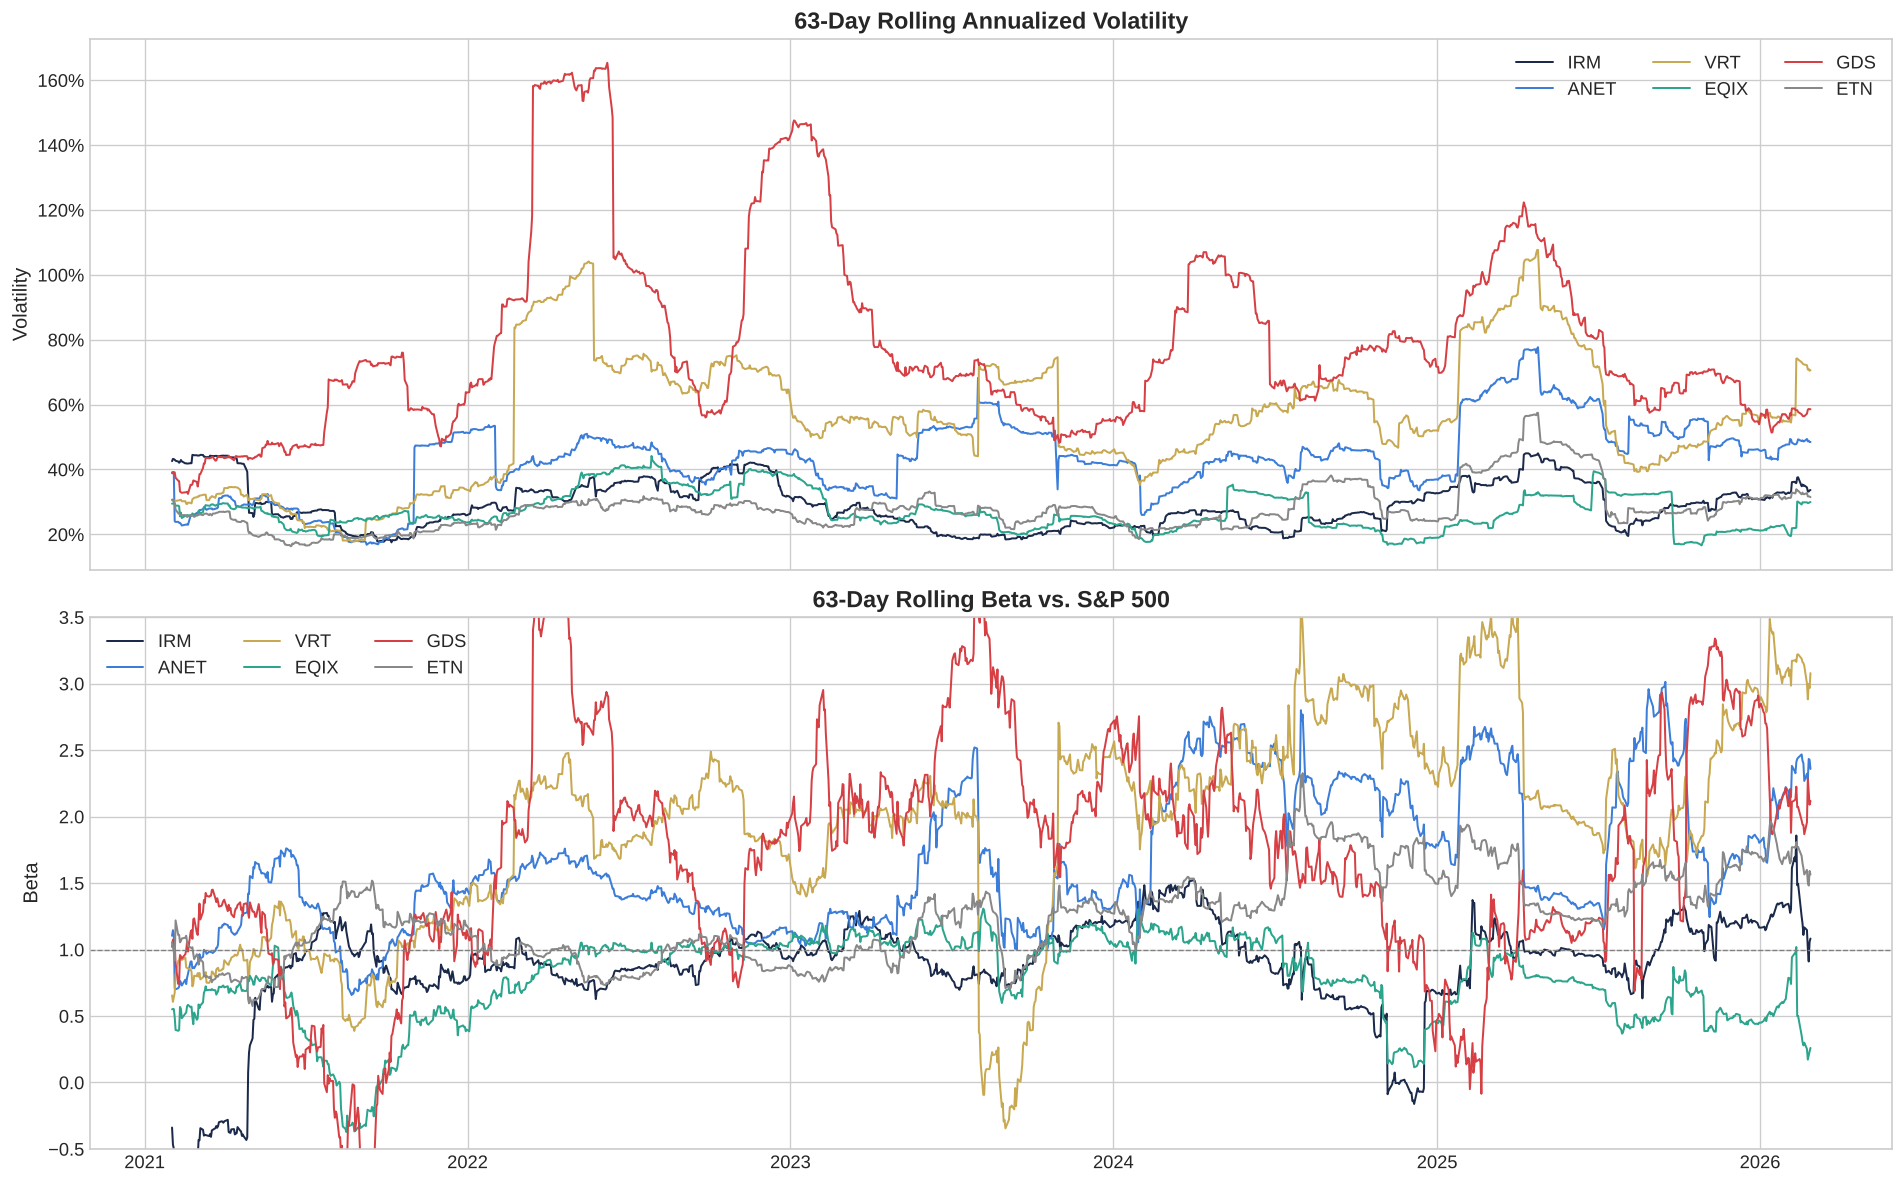

In [7]:
ROLLING = 63
top_6 = [t for t in ['IRM', 'ANET', 'VRT', 'EQIX', 'GDS', 'ETN'] if t in daily_returns.columns]

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

for i, t in enumerate(top_6):
    rv = daily_returns[t].rolling(ROLLING).std() * np.sqrt(252)
    axes[0].plot(rv.index, rv, label=t, linewidth=1.2, color=PALETTE[i])
axes[0].set_title('63-Day Rolling Annualized Volatility', fontweight='bold')
axes[0].set_ylabel('Volatility')
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[0].legend(ncol=3)

if BENCHMARK in daily_returns.columns:
    spy_var = daily_returns[BENCHMARK].rolling(ROLLING).var()
    for i, t in enumerate(top_6):
        cov_ts = daily_returns[t].rolling(ROLLING).cov(daily_returns[BENCHMARK])
        beta_ts = cov_ts / spy_var
        axes[1].plot(beta_ts.index, beta_ts, label=t, linewidth=1.2, color=PALETTE[i])
    axes[1].axhline(1.0, color='gray', linestyle='--', linewidth=0.8)
    axes[1].set_title('63-Day Rolling Beta vs. S&P 500', fontweight='bold')
    axes[1].set_ylabel('Beta')
    axes[1].legend(ncol=3)
    axes[1].set_ylim(-0.5, 3.5)

plt.tight_layout()
plt.show()


### 2.4 Distributions and normality

Three diagnostics: skewness, excess kurtosis, and the Jarque-Bera test, which combines them into

$$JB = \frac{n}{6}\left(S^2 + \frac{(K-3)^2}{4}\right) \sim \chi^2_2$$

under the null of normality.

I expected the test to reject for essentially every name. It rejected for two of nineteen, GDS and Honeywell. That is not evidence that these returns are normal, and the reasons are worth separating.

The test is run on monthly returns, and aggregating twenty-odd daily returns into one pulls the distribution toward normality by the central limit theorem; the fat tails that dominate daily data are much weaker at monthly frequency. And with only 64 observations the test has little power: the Jarque-Bera statistic is asymptotically chi-squared, and at this sample size it fails to reject quite large departures from normality. Failing to reject is a statement about the test, not about the data. The same names at daily frequency would reject almost without exception.

What still matters is direction and magnitude: negative skew means the large moves are concentrated on the downside, and excess kurtosis means they arrive more often than a Gaussian allows.

Both have a direct consequence for section 7. Parametric VaR computed as $\mu + z_\alpha \sigma$ assumes normality, and under leptokurtosis it understates the 99% loss while often being roughly correct at 95%. The size of the understatement scales with the excess kurtosis measured here, which is why I report historical and parametric VaR side by side rather than choosing one.

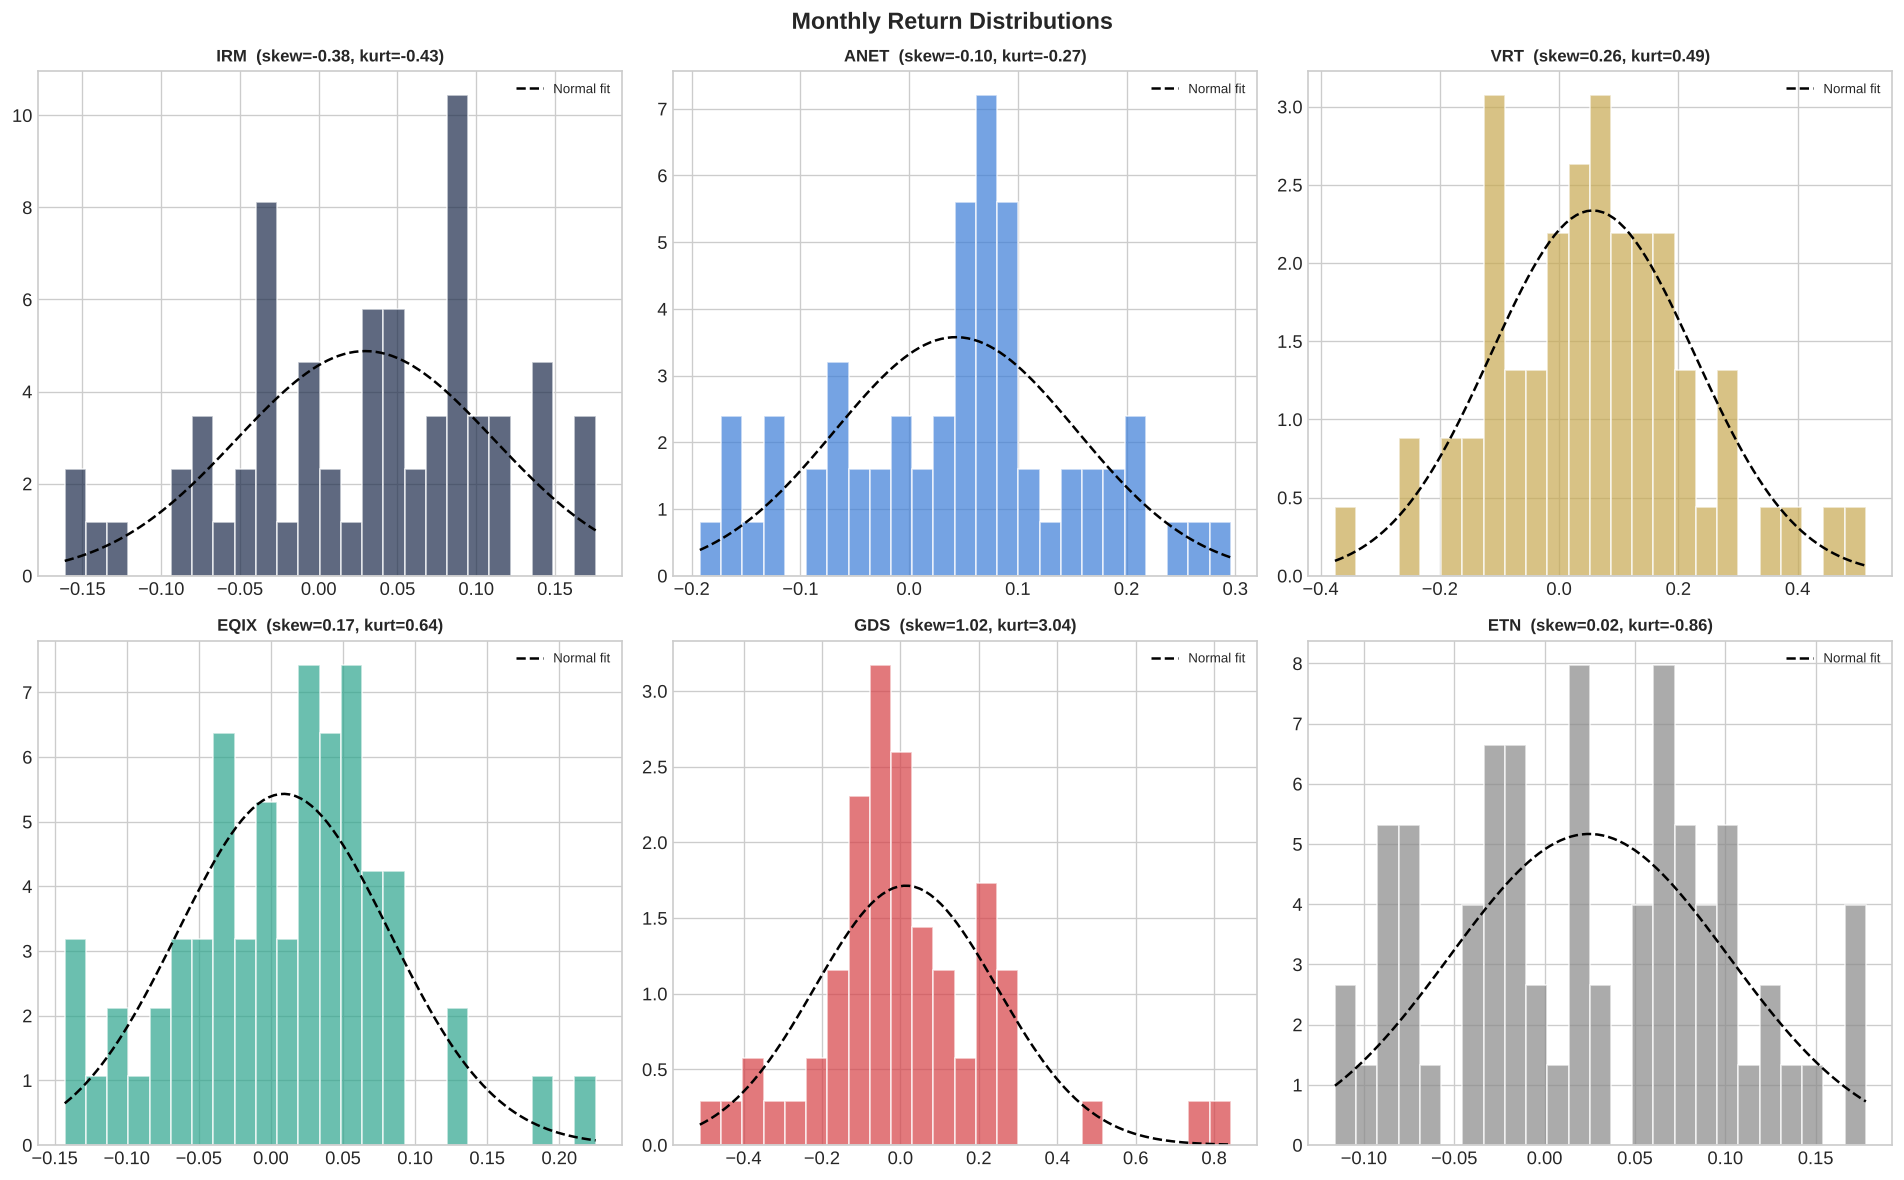

Jarque-Bera Normality Test:

Ticker      JB Stat    p-value  Normal?
--------------------------------------
EQIX           0.96     0.6195      Yes
DLR            1.95     0.3779      Yes
AMT            0.84     0.6575      Yes
CCI            5.32     0.0699      Yes
IRM            2.12     0.3459      Yes
GDS           30.21     0.0000       No
VNET           4.53     0.1038      Yes
VRT            1.02     0.6019      Yes
ANET           0.43     0.8081      Yes
CSCO           0.75     0.6883      Yes
MRVL           2.24     0.3265      Yes
SBGSY          0.11     0.9467      Yes
ETN            2.09     0.3518      Yes
JCI            0.86     0.6494      Yes
HON           19.25     0.0001       No
GNRC           2.11     0.3485      Yes
CAT            1.40     0.4972      Yes
DTCR           0.38     0.8268      Yes
SRVR           0.67     0.7169      Yes


In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Monthly Return Distributions', fontsize=14, fontweight='bold')

for ax, t in zip(axes.flat, top_6):
    data = monthly_returns[t].dropna()
    ax.hist(data, bins=25, density=True, alpha=0.7, color=PALETTE[top_6.index(t)], edgecolor='white')
    
    mu_fit, sig_fit = data.mean(), data.std()
    x = np.linspace(data.min(), data.max(), 100)
    ax.plot(x, norm.pdf(x, mu_fit, sig_fit), 'k--', linewidth=1.5, label='Normal fit')
    
    ax.set_title(f'{t}  (skew={data.skew():.2f}, kurt={data.kurt():.2f})', fontweight='bold', fontsize=10)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# Jarque-Bera tests
print("Jarque-Bera Normality Test:\n")
print(f"{'Ticker':<8} {'JB Stat':>10} {'p-value':>10} {'Normal?':>8}")
print("-" * 38)
for t in ACTIVE_TICKERS:
    stat, p = jarque_bera(monthly_returns[t].dropna())
    print(f"{t:<8} {stat:>10.2f} {p:>10.4f} {'Yes' if p > 0.05 else 'No':>8}")


## 3. Fama-French five-factor decomposition

The question this section answers is whether the portfolio's return is explained by exposures that can be bought cheaply elsewhere. Each asset's excess return is regressed on the five factors:

$$R_i - R_f = \alpha_i + \beta_{\mathrm{MKT}}(R_m - R_f) + \beta_{\mathrm{SMB}}\mathrm{SMB} + \beta_{\mathrm{HML}}\mathrm{HML} + \beta_{\mathrm{RMW}}\mathrm{RMW} + \beta_{\mathrm{CMA}}\mathrm{CMA} + \varepsilon_i$$

The factors are market, size, value, profitability and investment. Fama and French (2015) added the last two after showing that the profitability and investment patterns in average returns were not captured by the original three-factor model.

The coefficient of interest is $\alpha$, the average return unexplained by factor exposure. If it is indistinguishable from zero, the thesis reduces to a particular combination of size, value and profitability tilts, reproducible with factor ETFs at a fraction of the cost and without the single-name risk.

My prior was that the data centre REITs would load positively on value and the networking names negatively, with the investment factor picking up the capital intensity of the buildout as a negative CMA loading.

The second half held and the first did not. Arista loads at -1.18 on HML, as expected for a growth name. But the REITs load **negatively** on value too: Equinix at -0.83, Iron Mountain at -0.58, Digital Realty at -0.56. Over this window the market priced data centre landlords as growth assets rather than as the income vehicles the REIT structure suggests. The CMA loadings went the opposite way to my prior, positive and large for Iron Mountain (1.26) and Equinix (0.67). With 64 monthly observations the standard errors on individual loadings are wide, so these are descriptive patterns rather than estimates I would lean on.

The more important number is $R^2$, which ranges from 0.03 for the Chinese operators to 0.65 for Schneider. For most names the five factors explain well under half the variance, so a large share of what this portfolio does is not a repackaging of known factor exposures, for better or worse.

### On the alpha t-statistics

Alphas are flagged as significant at $|t| > 2$. That threshold is wrong here and I am flagging it rather than using it uncritically. Testing 19 assets at the 5% level produces roughly one spurious rejection by chance alone. Harvey, Liu and Zhu (2016) argue that after accounting for the scale of the search that produced the published factor literature, the appropriate hurdle is closer to $|t| > 3$. The flags below should be read as descriptive, not as evidence of skill. One name clears $|t| > 2$, Arista at 2.72; Iron Mountain and Vertiv sit just under it at 1.99 and 1.90. None clears 3.

### A failure mode in the factor construction

The factor loader tries three sources in order: the `getFamaFrenchFactors` package, a direct download from Ken French's data library, and finally a set of ETF-based proxies. The proxy branch is a reasonable fallback, since IWM minus SPY is a defensible stand-in for SMB and IWD minus IWF for HML.

The last resort inside that branch is not reasonable. If the proxy ETFs are also unavailable it generates a factor from `np.random.normal`, which produces a regression against noise that will return an $R^2$ near zero and an alpha that absorbs the entire return, with no indication anything went wrong. That is worse than failing. Check the printed output below and confirm which source actually loaded before reading any coefficient in this section.

In [9]:
# ══════════════════════════════════════════════════════════════
# FAMA-FRENCH FACTOR CONSTRUCTION
# ══════════════════════════════════════════════════════════════

# Attempt 0: frozen snapshot written by fetch_data.py
ff5 = None
FF_SNAPSHOT = os.path.join('data_cache', 'ff5_monthly.csv')
if os.path.exists(FF_SNAPSHOT):
    ff5 = pd.read_csv(FF_SNAPSHOT, index_col=0, parse_dates=True)
    print("✓ Fama-French factors loaded from frozen snapshot")

# Attempt 1: getFamaFrenchFactors library
try:
    if ff5 is not None:
        raise StopIteration  # snapshot already loaded, skip
    import getFamaFrenchFactors as gff
    ff_raw = gff.famaFrench5Factor(frequency='m')
    ff_raw.columns = ['Date', 'Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'RF']
    ff_raw['Date'] = pd.to_datetime(ff_raw['Date'])
    ff5 = ff_raw.set_index('Date') / 100
    print("✓ Fama-French factors loaded via getFamaFrenchFactors")
except Exception as e:
    if ff5 is None:
        print(f"getFamaFrenchFactors failed: {e}")

# Attempt 2: Ken French website
if ff5 is None:
    try:
        import urllib.request, zipfile, io
        url = 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Research_Data_5_Factors_2x3_CSV.zip'
        response = urllib.request.urlopen(url, timeout=10)
        zf = zipfile.ZipFile(io.BytesIO(response.read()))
        csv_name = zf.namelist()[0]
        ff_raw = pd.read_csv(zf.open(csv_name), skiprows=3, index_col=0)
        # Find where annual data starts
        for idx_pos, val in enumerate(ff_raw.index):
            try:
                int(str(val).strip())
            except:
                break
        ff5 = ff_raw.iloc[:idx_pos].copy()
        ff5.index = pd.to_datetime(ff5.index.astype(str).str.strip(), format='%Y%m') + pd.offsets.MonthEnd(0)
        ff5.columns = ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'RF']
        ff5 = ff5.astype(float) / 100
        print("✓ Fama-French factors loaded from Ken French website")
    except Exception as e:
        print(f"Ken French download failed: {e}")

# Attempt 3: ETF-based proxies
if ff5 is None:
    print("→ Constructing proxy factors from available data...")
    mr = monthly_returns
    
    factors_dict = {}
    
    # MKT-RF
    if BENCHMARK in mr.columns:
        factors_dict['Mkt-RF'] = mr[BENCHMARK] - RF_MONTHLY
    else:
        factors_dict['Mkt-RF'] = mr[ACTIVE_TICKERS].mean(axis=1) - RF_MONTHLY
    
    # SMB proxy: IWM - SPY (or synthetic)
    if 'IWM' in mr.columns and BENCHMARK in mr.columns:
        factors_dict['SMB'] = mr['IWM'] - mr[BENCHMARK]
    else:
        # Use small-cap proxy: average of smaller names minus large names
        small = [t for t in ['GNRC', 'VNET', 'GDS', 'VRT'] if t in mr.columns]
        large = [t for t in ['EQIX', 'AMT', 'CAT', 'HON'] if t in mr.columns]
        if small and large:
            factors_dict['SMB'] = mr[small].mean(axis=1) - mr[large].mean(axis=1)
        else:
            factors_dict['SMB'] = None  # replaced below: fabricating a factor from noise is worse than failing
    
    # HML proxy: IWD - IWF (or synthetic)
    if 'IWD' in mr.columns and 'IWF' in mr.columns:
        factors_dict['HML'] = mr['IWD'] - mr['IWF']
    else:
        # Value vs growth proxy
        value = [t for t in ['DLR', 'AMT', 'CCI', 'CSCO'] if t in mr.columns]
        growth = [t for t in ['ANET', 'VRT', 'MRVL'] if t in mr.columns]
        if value and growth:
            factors_dict['HML'] = mr[value].mean(axis=1) - mr[growth].mean(axis=1)
        else:
            factors_dict['HML'] = None  # replaced below: fabricating a factor from noise is worse than failing
    
    # RMW and CMA — simplified proxies
    factors_dict['RMW'] = None  # replaced below: fabricating a factor from noise is worse than failing
    factors_dict['CMA'] = None  # replaced below: fabricating a factor from noise is worse than failing
    absent = [k for k, v in factors_dict.items() if v is None]
    if absent:
        raise RuntimeError(
            f"No genuine data for factors {absent}. An earlier version filled these "
            f"with np.random.normal, which yields a regression against noise: R-squared "
            f"near zero and an alpha that absorbs the entire return, with no warning. "
            f"Run fetch_data.py to create data_cache/ff5_monthly.csv instead.")
    factors_dict['RF'] = RF_MONTHLY
    
    ff5 = pd.DataFrame(factors_dict)
    print("✓ Proxy factors constructed from portfolio data")

# ── Align dates ──
# Use the intersection of both indices; fall back to ff5's own index for proxy factors
common_idx = ff5.index.intersection(monthly_returns.index)
if len(common_idx) == 0:
    # Proxy factors share the same index — use it directly
    common_idx = ff5.index[ff5.index.isin(monthly_returns.index)]
if len(common_idx) == 0:
    # Last resort: just use ff5 index (created from monthly_returns)
    common_idx = ff5.index

ff5_a = ff5.reindex(common_idx).dropna()
mr_a = monthly_returns.reindex(common_idx).dropna(how='all')
# Re-align after dropping NAs
common_idx = ff5_a.index.intersection(mr_a.index)
ff5_a = ff5_a.loc[common_idx]
mr_a = mr_a.loc[common_idx]

print(f"\nAligned {len(common_idx)} months for factor analysis")
if len(common_idx) > 0:
    print(f"Date range: {common_idx[0].strftime('%Y-%m')} to {common_idx[-1].strftime('%Y-%m')}")
else:
    print("WARNING: No overlapping dates — factor analysis may be limited")


✓ Fama-French factors loaded from frozen snapshot

Aligned 64 months for factor analysis
Date range: 2020-11 to 2026-02


In [10]:
# ══════════════════════════════════════════════════════════════
# RUN FF5 REGRESSIONS
# ══════════════════════════════════════════════════════════════

factors = ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']
X = sm.add_constant(ff5_a[factors])

ff_results = {}

print(f"{'Ticker':<8} {'Alpha(ann)':>10} {'t(alpha)':>9} {'MKT':>7} {'SMB':>7} {'HML':>7} {'RMW':>7} {'CMA':>7} {'R-sq':>6}")
print("=" * 78)

try:
    rf_series = ff5_a['RF']
except:
    rf_series = RF_MONTHLY

for t in ACTIVE_TICKERS:
    if t not in mr_a.columns:
        continue
    y = mr_a[t] - rf_series
    try:
        model = sm.OLS(y, X, missing='drop').fit()
        alpha_ann = model.params['const'] * 12
        t_alpha = model.tvalues['const']
        betas = model.params[factors]
        
        ff_results[t] = {
            'alpha_ann': alpha_ann, 't_alpha': t_alpha, 'r_sq': model.rsquared,
            **{f'beta_{f}': betas[f] for f in factors}, 'model': model,
        }
        
        sig = '*' if abs(t_alpha) > 2 else ' '
        print(f"{t:<8} {alpha_ann:>9.1%}{sig} {t_alpha:>8.2f} {betas['Mkt-RF']:>7.2f} "
              f"{betas['SMB']:>7.2f} {betas['HML']:>7.2f} {betas['RMW']:>7.2f} "
              f"{betas['CMA']:>7.2f} {model.rsquared:>6.2f}")
    except Exception as ex:
        print(f"{t:<8} REGRESSION FAILED: {ex}")

print("\n* = significant at 5% level (|t| > 2)")


Ticker   Alpha(ann)  t(alpha)     MKT     SMB     HML     RMW     CMA   R-sq
EQIX          0.2%      0.02    0.82    0.19   -0.83    0.46    0.67   0.38
DLR          -3.4%     -0.36    0.90    0.00   -0.56    0.62    0.32   0.41
AMT         -14.2%     -1.34    0.80    0.09   -0.04    0.66    0.17   0.27
CCI         -20.7%     -1.85    0.91   -0.02    0.08    0.47    0.07   0.28
IRM          20.5%      1.99    1.05    0.43   -0.58    0.11    1.26   0.44
GDS          15.2%      0.39    0.43   -0.19   -1.03   -0.46    1.61   0.03
VNET          9.2%      0.27    0.25   -0.37    0.44   -1.65    0.01   0.04
VRT          47.0%      1.90    1.74   -0.40   -0.51   -0.08   -0.17   0.26
ANET         36.4%*     2.72    1.39    0.06   -1.18    0.68    0.41   0.49
CSCO          4.2%      0.53    0.91    0.30   -0.31    0.65    0.37   0.47
MRVL         12.3%      0.65    1.80   -0.23   -0.83   -0.73    0.01   0.43
SBGSY         3.3%      0.41    1.41   -0.02   -0.38    0.35    0.38   0.65
ETN        

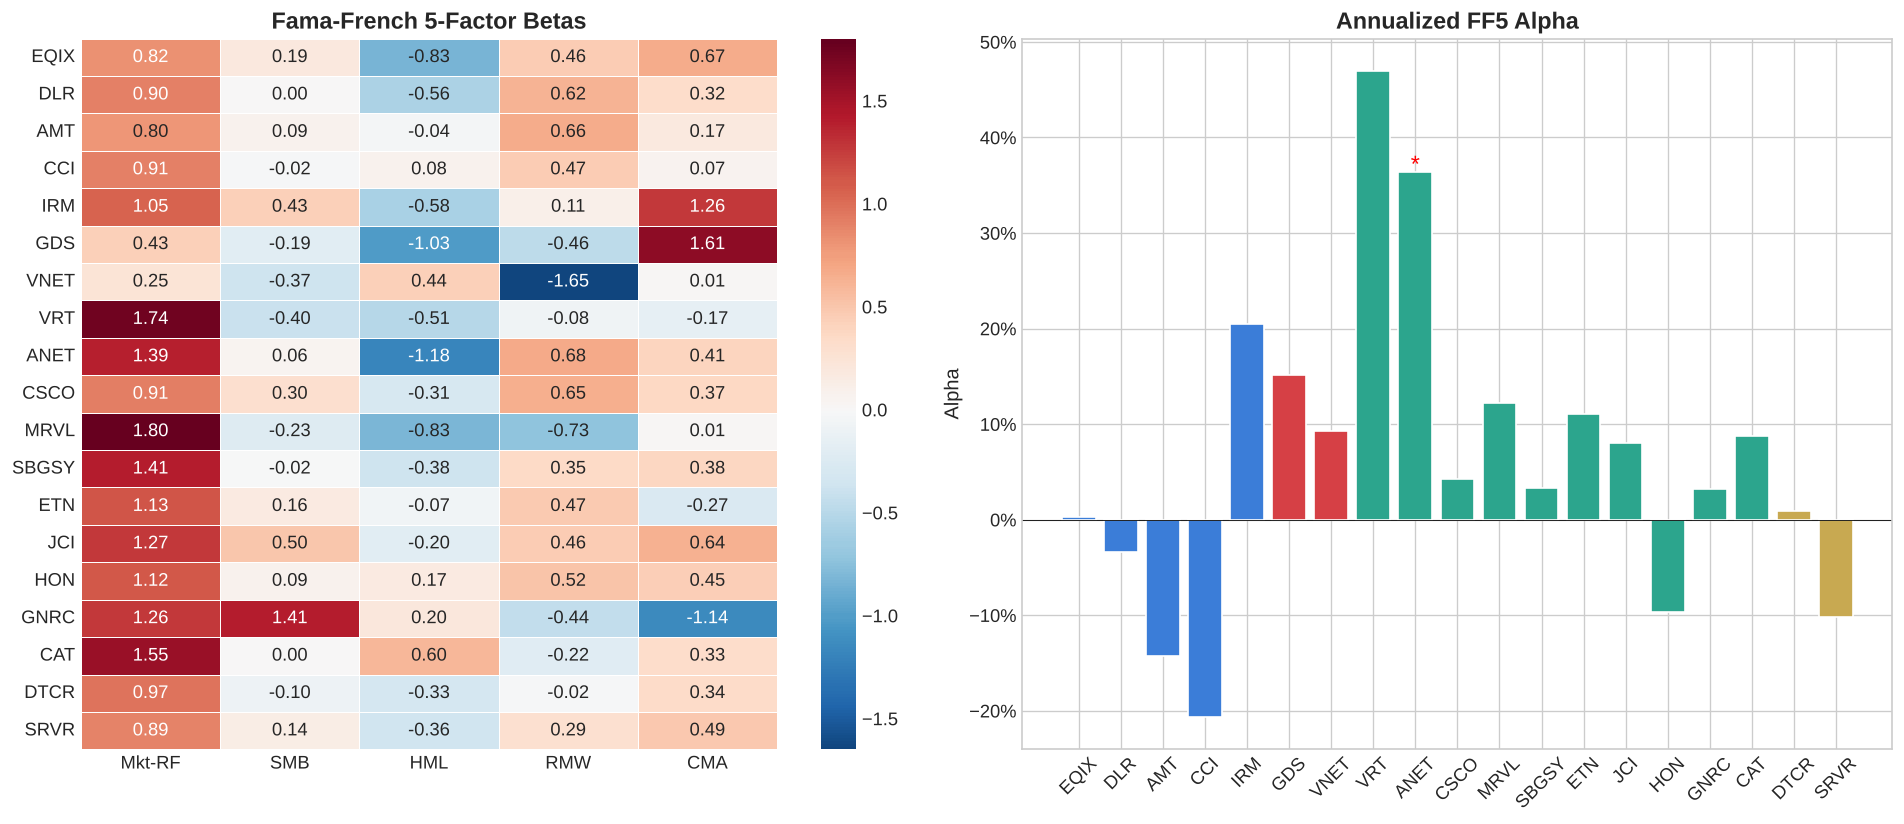

In [11]:
# ── Factor exposure heatmap ──
if not ff_results:
    print("No factor results — skipping visualization.")
    ff_df = pd.DataFrame()
else:
    ff_df = pd.DataFrame(ff_results).T
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    beta_cols = [c for c in ff_df.columns if c.startswith('beta_')]
    beta_mtx = ff_df[beta_cols].rename(columns={c: c.replace('beta_', '') for c in beta_cols}).astype(float)
    sns.heatmap(beta_mtx, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
                ax=axes[0], linewidths=0.5)
    axes[0].set_title('Fama-French 5-Factor Betas', fontweight='bold')
    
    cluster_colors = {'REIT': COLORS['blue'], 'Asia': COLORS['red'],
                      'Infrastructure': COLORS['teal'], 'ETF': COLORS['gold']}
    bar_colors = [cluster_colors.get(TICKER_CLUSTER.get(t, ''), COLORS['gray']) for t in ff_df.index]
    axes[1].bar(ff_df.index, ff_df['alpha_ann'], color=bar_colors, edgecolor='white')
    axes[1].axhline(0, color='black', linewidth=0.5)
    axes[1].set_title('Annualized FF5 Alpha', fontweight='bold')
    axes[1].set_ylabel('Alpha')
    axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    axes[1].tick_params(axis='x', rotation=45)
    for idx_pos, t in enumerate(ff_df.index):
        if abs(ff_df.loc[t, 't_alpha']) > 2:
            axes[1].annotate('*', (idx_pos, ff_df.loc[t, 'alpha_ann']), ha='center', fontsize=14, color='red')
    
    plt.tight_layout()
    plt.show()


## 4. Portfolio optimisation

### 4.1 The optimiser

Three objectives, all long-only and fully invested.

**Maximum Sharpe (tangency).** Maximises $(\mu^\top w - r_f)/\sqrt{w^\top \Sigma w}$. Solved with SLSQP from five random Dirichlet starting points, keeping the best. The multi-start is not decoration: the Sharpe objective under the budget and bound constraints is not concave in $w$, so a single start can terminate at a local optimum. Reporting the best of several starts is the cheap defence.

**Minimum variance.** Minimises $w^\top \Sigma w$ subject to the budget constraint. This is the one portfolio on the frontier that does not require an expected return estimate at all, which given section 1.3 makes it the most robustly estimated point available. Its out-of-sample performance frequently beats the tangency portfolio for exactly that reason, and that result should be read as a statement about estimation error rather than about risk premia.

**Capped maximum Sharpe.** The tangency portfolio with a 15% position limit. The cap is a blunt instrument that substitutes for a proper treatment of estimation error, but it is also what an actual mandate would impose, so it is the realistic comparator.

### Effective N

Alongside each portfolio I report $1/\sum_i w_i^2$, the inverse Herfindahl index. For an equal-weighted portfolio of $n$ assets this equals $n$; for a portfolio concentrated in one name it approaches 1. It converts the weight vector into a single interpretable number: how many genuinely independent positions the portfolio behaves like. An unconstrained tangency portfolio over 15 names routinely produces an effective N below 4, which is the concentration problem made legible.


In [12]:
# ══════════════════════════════════════════════════════════════
# OPTIMIZATION ENGINE
# ══════════════════════════════════════════════════════════════

def portfolio_stats(w, mu, cov, rf=RF_ANNUAL):
    """Annualized return, volatility, and Sharpe ratio."""
    ret = np.sum(mu * w) * 12
    vol = np.sqrt(np.dot(w.T, np.dot(cov * 12, w)))
    sr = (ret - rf) / vol if vol > 0 else 0
    return ret, vol, sr

def max_sharpe_portfolio(mu, cov, rf=RF_ANNUAL, max_weight=None):
    """Tangency portfolio — maximize Sharpe ratio, long-only."""
    n = len(mu)
    bounds = tuple((0, max_weight or 1.0) for _ in range(n))
    constraints = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}
    
    def neg_sharpe(w):
        _, _, sr = portfolio_stats(w, mu, cov, rf)
        return -sr
    
    # Try multiple starting points for robustness
    best_result = None
    for _ in range(5):
        w0 = np.random.dirichlet(np.ones(n))
        result = minimize(neg_sharpe, w0, method='SLSQP', bounds=bounds,
                         constraints=constraints, options={'maxiter': 2000, 'ftol': 1e-12})
        if best_result is None or result.fun < best_result.fun:
            best_result = result
    
    return best_result.x

def min_var_portfolio(cov, max_weight=None):
    """Global minimum variance portfolio."""
    n = cov.shape[0]
    bounds = tuple((0, max_weight or 1.0) for _ in range(n))
    constraints = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}
    result = minimize(lambda w: np.dot(w.T, np.dot(cov * 12, w)),
                      np.ones(n)/n, method='SLSQP', bounds=bounds, constraints=constraints)
    return result.x

def efficient_frontier(mu, cov, n_pts=80, rf=RF_ANNUAL):
    """Compute the efficient frontier."""
    w_min = min_var_portfolio(cov)
    ret_min = np.sum(mu * w_min) * 12
    ret_max = np.max(mu) * 12 * 0.95
    
    targets = np.linspace(ret_min, ret_max, n_pts)
    vols = []
    n = len(mu)
    bounds = tuple((0, 1) for _ in range(n))
    
    for tgt in targets:
        cons = [
            {'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0},
            {'type': 'eq', 'fun': lambda w, t=tgt: np.sum(w * mu) * 12 - t},
        ]
        res = minimize(lambda w: np.sqrt(np.dot(w.T, np.dot(cov * 12, w))),
                       np.ones(n)/n, method='SLSQP', bounds=bounds, constraints=cons)
        vols.append(res.fun if res.success else np.nan)
    
    return targets, np.array(vols)

print("Optimization engine loaded.")


Optimization engine loaded.


### 4.2 Cluster-level optimisation

Optimising within each cluster before combining across them imposes structure that the full-universe optimiser would otherwise have to discover from noisy data.

This is a crude form of the hierarchical approach. Lopez de Prado's Hierarchical Risk Parity (2016) formalises it properly: cluster the correlation matrix by a tree, then allocate by recursive bisection, which avoids inverting the covariance matrix entirely and produces markedly more stable out-of-sample weights. What I do here is the manual version, with clusters defined by economic reasoning rather than by a linkage algorithm. The benefit is interpretability; the cost is that the cluster definitions are my judgement and not a property of the data.

### What it produced

Three of the four clusters collapse to a single name: the REIT cluster to 100% Iron Mountain, the Asian cluster to 100% GDS, the ETF cluster to 100% DTCR. Only the infrastructure cluster keeps four names. This is the error-maximisation problem of section 2.2 in its plainest form. A long-only maximum Sharpe optimiser handed noisy means puts everything on whichever asset happened to have the best realised Sharpe ratio, and a within-cluster allocation that holds one name is not diversified in any sense the clustering was meant to deliver.

In [13]:
cluster_results = {}

for cname, tickers in CLUSTERS.items():
    if len(tickers) < 2:
        print(f"\nSkipping {cname} — fewer than 2 assets")
        continue
    
    mu = monthly_returns[tickers].mean()
    cov = monthly_returns[tickers].cov()
    w = max_sharpe_portfolio(mu.values, cov.values)
    ret, vol, sr = portfolio_stats(w, mu.values, cov.values)
    
    cluster_results[cname] = {'tickers': tickers, 'weights': dict(zip(tickers, w)),
                               'return': ret, 'volatility': vol, 'sharpe': sr}
    
    print(f"\n{'='*50}")
    print(f"  {cname} Cluster — Max Sharpe Portfolio")
    print(f"{'='*50}")
    print(f"  Return: {ret:.2%}   Vol: {vol:.2%}   Sharpe: {sr:.2f}")
    for t, wt in sorted(zip(tickers, w), key=lambda x: -x[1]):
        if wt > 0.005:
            print(f"    {t:<8} {wt:.2%}")



  REIT Cluster — Max Sharpe Portfolio
  Return: 35.39%   Vol: 28.33%   Sharpe: 1.09
    IRM      100.00%

  Asia Cluster — Max Sharpe Portfolio
  Return: 16.87%   Vol: 80.64%   Sharpe: 0.15
    GDS      100.00%

  Infrastructure Cluster — Max Sharpe Portfolio
  Return: 46.18%   Vol: 29.04%   Sharpe: 1.44
    ANET     48.36%
    JCI      25.22%
    VRT      13.38%
    CAT      13.04%

  ETF Cluster — Max Sharpe Portfolio
  Return: 14.54%   Vol: 21.29%   Sharpe: 0.47
    DTCR     100.00%


### 4.3 Full optimisation and the efficient frontier

### A bias to be explicit about

The universe is reduced to 15 names before optimisation by ranking on in-sample Sharpe ratio and keeping the top 15. This is a selection step performed on the same data the optimiser then uses, and it inflates every performance figure downstream of it. Names that happened to do well in this sample are retained; names that happened to do badly are dropped. The optimiser is then handed a universe pre-filtered for good luck.

The effect is not small and it does not stay in this section. The walk-forward backtest in section 6 runs on this already-filtered universe, which means its "out-of-sample" returns are not out of sample with respect to the selection decision. A walk-forward loop that re-estimates parameters correctly but inherits a universe chosen with full-sample knowledge is still contaminated, and this is one of the most common ways a backtest acquires look-ahead bias without anyone noticing.

I have left it in place and labelled it rather than fixing it here, because the companion notebook handles it properly with a temporal split and the comparison between the two is the point. When reading section 6, treat its Sharpe ratios as an upper bound rather than an estimate.

### The frontier

The frontier is traced by minimising variance subject to a sequence of target returns. Plotted alongside it are the individual assets, which should all sit inside the boundary, and the three optimised portfolios. The gap between the best single asset and the frontier is the diversification benefit, and the capped portfolio's distance below the unconstrained tangency point is the price of the position limit, measured in Sharpe ratio rather than asserted.


In [14]:
# ── Select top 15 tickers for full optimization ──
portfolio_tickers = [t for t in ACTIVE_TICKERS if t in monthly_returns.columns]
if len(portfolio_tickers) > 15:
    sharpes = {t: ((monthly_returns[t].mean()*12 - RF_ANNUAL) / 
                   (monthly_returns[t].std()*np.sqrt(12))) for t in portfolio_tickers}
    portfolio_tickers = sorted(sharpes, key=sharpes.get, reverse=True)[:15]

mu_full = monthly_returns[portfolio_tickers].mean()
cov_full = monthly_returns[portfolio_tickers].cov()

# ── Unconstrained tangency ──
w_tang = max_sharpe_portfolio(mu_full.values, cov_full.values)
ret_t, vol_t, sr_t = portfolio_stats(w_tang, mu_full.values, cov_full.values)

# ── Capped at 15% ──
w_cap = max_sharpe_portfolio(mu_full.values, cov_full.values, max_weight=0.15)
ret_c, vol_c, sr_c = portfolio_stats(w_cap, mu_full.values, cov_full.values)

# ── Min variance ──
w_mv = min_var_portfolio(cov_full.values)
ret_mv, vol_mv, sr_mv = portfolio_stats(w_mv, mu_full.values, cov_full.values)

# ── Results table ──
comp = pd.DataFrame({
    'Max Sharpe': [ret_t, vol_t, sr_t, 1/np.sum(w_tang**2)],
    'Capped 15%': [ret_c, vol_c, sr_c, 1/np.sum(w_cap**2)],
    'Min Variance': [ret_mv, vol_mv, sr_mv, 1/np.sum(w_mv**2)],
}, index=['Ann. Return', 'Ann. Volatility', 'Sharpe Ratio', 'Effective N'])

print("Portfolio Comparison:\n")
print(comp.to_string(float_format='{:.3f}'.format))

# ── Allocation comparison ──
alloc = pd.DataFrame({
    'Ticker': portfolio_tickers,
    'MaxSharpe': w_tang, 'Capped15': w_cap, 'MinVar': w_mv,
    'Cluster': [TICKER_CLUSTER.get(t, 'N/A') for t in portfolio_tickers]
}).sort_values('MaxSharpe', ascending=False)

print("\nTop allocations (Max Sharpe):")
for _, r in alloc.head(8).iterrows():
    print(f"  {r['Ticker']:<8} {r['MaxSharpe']:.2%}  ->  {r['Capped15']:.2%} (capped)   [{r['Cluster']}]")


Portfolio Comparison:

                 Max Sharpe  Capped 15%  Min Variance
Ann. Return           0.450       0.385         0.156
Ann. Volatility       0.271       0.249         0.178
Sharpe Ratio          1.493       1.368         0.623
Effective N           3.725       7.250         3.943

Top allocations (Max Sharpe):
  ANET     37.87%  ->  15.00% (capped)   [Infrastructure]
  IRM      30.40%  ->  15.00% (capped)   [REIT]
  VRT      14.64%  ->  15.00% (capped)   [Infrastructure]
  JCI      8.80%  ->  15.00% (capped)   [Infrastructure]
  CAT      4.16%  ->  15.00% (capped)   [Infrastructure]
  GDS      4.12%  ->  5.46% (capped)   [Asia]
  GNRC     0.00%  ->  0.00% (capped)   [Infrastructure]
  SBGSY    0.00%  ->  0.00% (capped)   [Infrastructure]


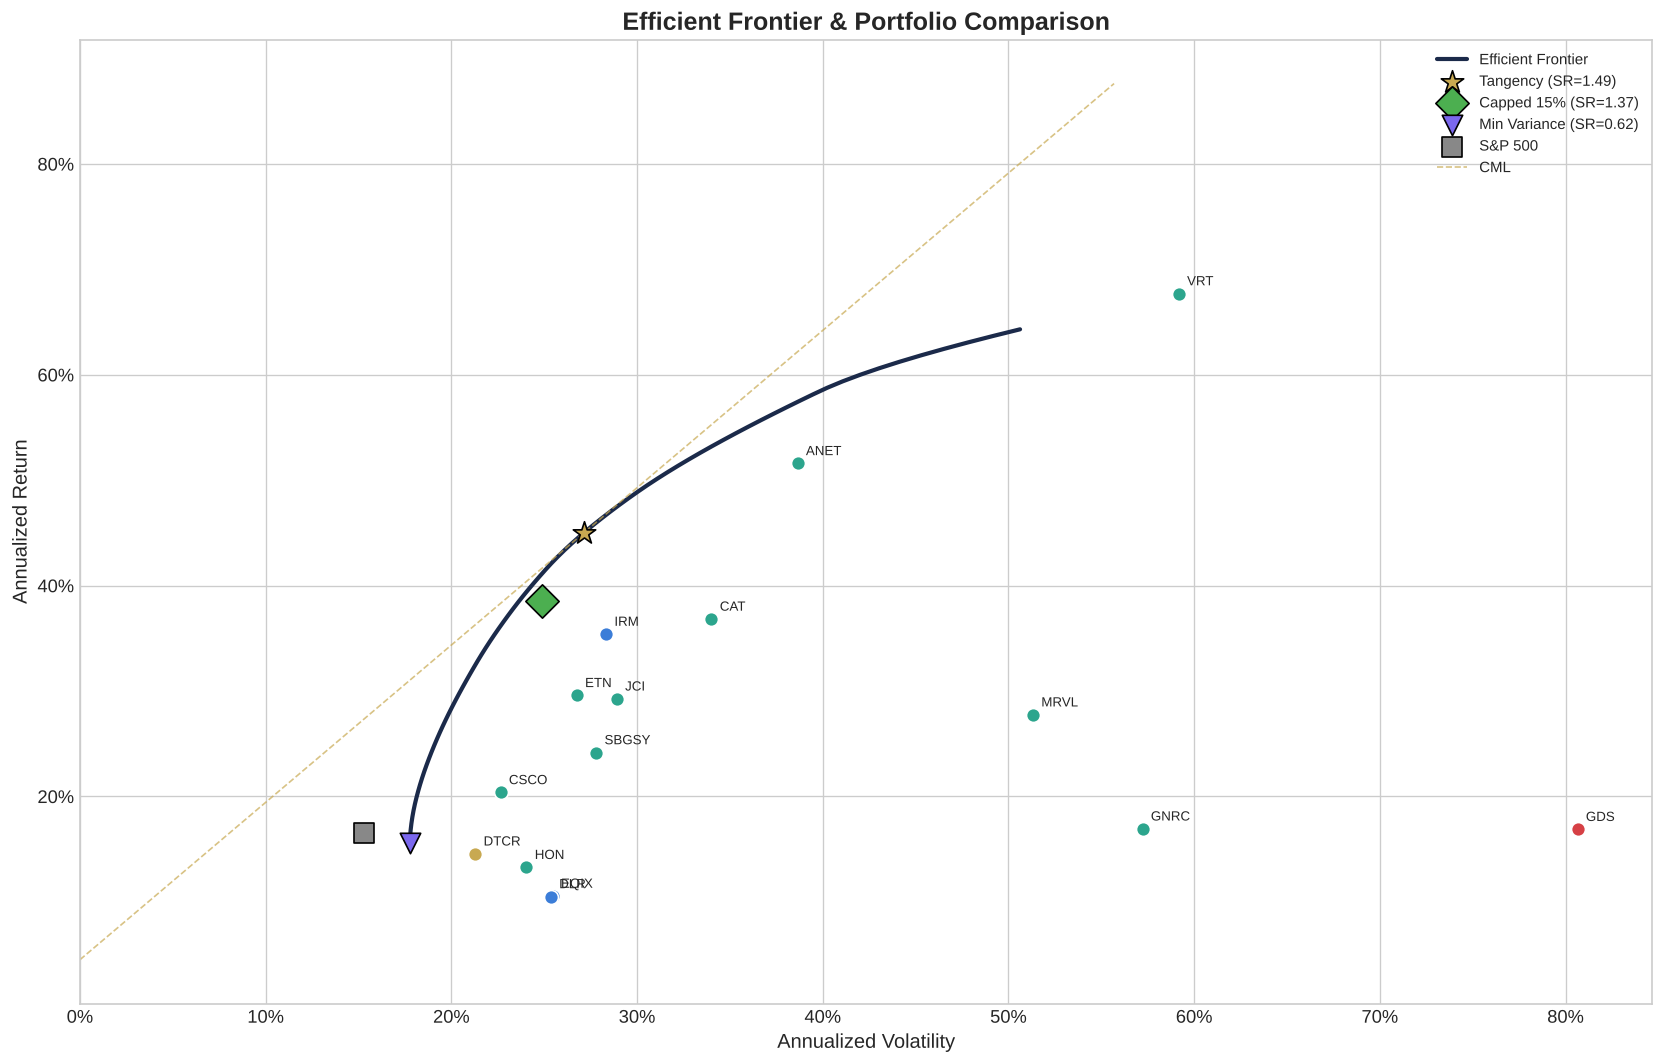

In [15]:
# ── Efficient Frontier Plot ──
tgt_rets, ef_vols = efficient_frontier(mu_full.values, cov_full.values)

fig, ax = plt.subplots(figsize=(14, 9))

valid = ~np.isnan(ef_vols)
ax.plot(ef_vols[valid], tgt_rets[valid], lw=2.5, color=COLORS['navy'], label='Efficient Frontier')

# Individual assets colored by cluster
for t in portfolio_tickers:
    r = mu_full[t] * 12
    v = monthly_returns[t].std() * np.sqrt(12)
    c = {'REIT': COLORS['blue'], 'Asia': COLORS['red'],
         'Infrastructure': COLORS['teal'], 'ETF': COLORS['gold']}.get(TICKER_CLUSTER.get(t), COLORS['gray'])
    ax.scatter(v, r, s=70, c=c, edgecolors='white', zorder=5)
    ax.annotate(t, (v, r), textcoords="offset points", xytext=(5, 5), fontsize=8)

# Portfolio points
ax.scatter(vol_t, ret_t, s=200, marker='*', c=COLORS['gold'], edgecolors='black', zorder=10,
           label=f'Tangency (SR={sr_t:.2f})')
ax.scatter(vol_c, ret_c, s=200, marker='D', c=COLORS['green'], edgecolors='black', zorder=10,
           label=f'Capped 15% (SR={sr_c:.2f})')
ax.scatter(vol_mv, ret_mv, s=150, marker='v', c=COLORS['purple'], edgecolors='black', zorder=10,
           label=f'Min Variance (SR={sr_mv:.2f})')

# SPY
if BENCHMARK in monthly_returns.columns:
    sr_spy = monthly_returns[BENCHMARK].mean()*12
    sv_spy = monthly_returns[BENCHMARK].std()*np.sqrt(12)
    ax.scatter(sv_spy, sr_spy, s=150, marker='s', c=COLORS['gray'], edgecolors='black', zorder=10,
               label=f'S&P 500')

# CML
cml_v = np.linspace(0, max(ef_vols[valid])*1.1, 100)
ax.plot(cml_v, RF_ANNUAL + sr_t * cml_v, '--', color=COLORS['gold'], lw=1, alpha=0.7, label='CML')

ax.set_xlabel('Annualized Volatility')
ax.set_ylabel('Annualized Return')
ax.set_title('Efficient Frontier & Portfolio Comparison', fontsize=15, fontweight='bold')
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend(fontsize=9)
ax.set_xlim(left=0)

plt.tight_layout()
plt.show()


## 5. Black-Litterman

Markowitz has a practical problem that has nothing to do with its mathematics: feed it historical means and it returns a portfolio nobody would hold. Black and Litterman (1992) solve it by changing where the expected returns come from.

### Reverse optimisation

Rather than estimating $\mu$ and solving for $w$, start from the weights the market already holds and ask what expected returns would make those weights optimal:

$$\Pi = \delta \Sigma w_{\mathrm{mkt}}$$

where $\delta$ is the market's risk aversion. $\Pi$ is the equilibrium prior. What makes this work is that the prior is internally consistent: a portfolio optimised on $\Pi$ alone returns $w_{\mathrm{mkt}}$ exactly. So an investor with no views holds the market, and deviates only to the extent they actually disagree with it.

### Blending in views

Views are expressed as $P\mu = Q + \varepsilon$, with $\varepsilon \sim N(0, \Omega)$. Each row of $P$ is a portfolio: a single 1 states an absolute view on one asset, a 1 and a $-1$ states a relative view. The posterior is the precision-weighted combination of prior and views:

$$\mu_{\mathrm{BL}} = \left[(\tau\Sigma)^{-1} + P^\top \Omega^{-1} P\right]^{-1}\left[(\tau\Sigma)^{-1}\Pi + P^\top \Omega^{-1} Q\right]$$

Confident views, meaning small $\Omega$, pull the posterior toward $Q$; uncertain views leave it near $\Pi$. Assets not named in any view still move, through their covariance with the ones that are, which is what stops the result from looking like a set of manual overrides.

I set $\Omega = \mathrm{diag}(\tau P \Sigma P^\top)$, following He and Litterman (1999). This makes the uncertainty of each view proportional to the variance of the portfolio that expresses it, so a view on a volatile name is automatically treated as less precise. It is a convenient default rather than a derived result.

### The views

Four, all modest and all expressed as monthly figures:

- Vertiv outperforms, on thermal and power demand from high-density AI racks
- Arista outperforms, on AI networking buildout
- Iron Mountain outperforms, on the data centre pivot
- Equinix outperforms GDS, on Chinese regulatory and funding risk

The last is relative and is the one I have most confidence in, because it expresses a risk differential rather than a growth forecast.

### Three problems with this implementation

The prior uses $w_{\mathrm{mkt}} = \mathbf{1}/n$, equal weights, as a stand-in for market capitalisation weights. This undercuts the main argument for the model. The equilibrium prior is meaningful because it is what the aggregate of all investors actually holds; an equal-weighted prior is just another arbitrary starting point, and $\Pi$ computed from it is not an equilibrium of anything. The fix is to weight by market capitalisation, which requires a share-count series the current data loader does not fetch.

The second was an outright error, now corrected. The posterior covariance $\Sigma_{\mathrm{BL}} = \Sigma + M$ was computed correctly and then passed through `.cov()` before reaching the optimiser, which computes the covariance between the columns of a covariance matrix. That is not a quantity with any meaning, and the weights it produced were not Black-Litterman weights in any sense. The posterior returns were never affected, which is what made it hard to spot: the printed table looked entirely reasonable while the portfolio derived from it was arbitrary.

It is worth noting how it survived. Both the correct and the incorrect object are square matrices of the right dimension, so nothing raised, nothing warned, and the optimiser returned a plausible-looking weight vector. A dimension check would not have caught it. The only thing that catches this class of error is reading the code back and asking what each object is, which is the argument for keeping the model implementation in `src/` where it can be tested rather than inline in a notebook cell.

The third is in how the views are written, and it is visible in the output. Each "outperforms" view is specified as an absolute expected return, and for Vertiv that return, 1.5% a month or 18% a year, is *below* the 21.8% the equilibrium prior already assigns it. A view labelled as bullish therefore pulls Vertiv's posterior down, to 21.0%. The label and the number say opposite things, and only the number reaches the model. Absolute views have to be stated relative to the prior they are meant to move, or expressed as relative views against a benchmark, which is what the Equinix-against-GDS view does and why it is the only one behaving as intended: it pushes GDS down by 4.6 points.

In [16]:
# ══════════════════════════════════════════════════════════════
# BLACK-LITTERMAN
# ══════════════════════════════════════════════════════════════

def black_litterman(Sigma, w_mkt, P, Q, tau=0.05, delta=2.5):
    """Black-Litterman posterior expected returns."""
    pi = delta * Sigma @ w_mkt                          # Implied equilibrium
    Omega = np.diag(np.diag(tau * P @ Sigma @ P.T))     # View uncertainty
    
    tS_inv = np.linalg.inv(tau * Sigma)
    O_inv = np.linalg.inv(Omega)
    
    M = np.linalg.inv(tS_inv + P.T @ O_inv @ P)
    mu_bl = M @ (tS_inv @ pi + P.T @ O_inv @ Q)
    Sigma_bl = Sigma + M
    return pi, mu_bl, Sigma_bl

# ── Build views ──
n = len(portfolio_tickers)
idx = {t: i for i, t in enumerate(portfolio_tickers)}
views, view_descs = [], []

# Thematic views on the AI data center buildout
view_specs = [
    ('VRT',  None,   0.015,  "Vertiv outperforms: AI cooling/power surge"),
    ('ANET', None,   0.012,  "Arista outperforms: AI networking demand"),
    ('IRM',  None,   0.010,  "IRM outperforms: data center pivot momentum"),
    ('EQIX', 'GDS',  0.005,  "EQIX beats GDS: China regulatory risk"),
]

for spec in view_specs:
    if spec[0] in idx and (spec[1] is None or spec[1] in idx):
        v = np.zeros(n)
        v[idx[spec[0]]] = 1.0
        if spec[1]:
            v[idx[spec[1]]] = -1.0
        views.append(v)
        view_descs.append((spec[2], spec[3]))

if views:
    P = np.array(views)
    Q = np.array([v[0] for v in view_descs])
    
    w_mkt = np.ones(n) / n  # Equal-weight prior (proxy for mkt-cap)
    Sigma_m = cov_full.values
    
    pi, mu_bl, Sigma_bl = black_litterman(Sigma_m, w_mkt, P, Q)
    
    print("Black-Litterman Results:\n")
    print(f"{'Ticker':<8} {'Equilibrium':>12} {'BL Posterior':>12} {'Shift':>10}")
    print("-" * 45)
    for i, t in enumerate(portfolio_tickers):
        print(f"{t:<8} {pi[i]*12:>11.2%} {mu_bl[i]*12:>11.2%} {(mu_bl[i]-pi[i])*12:>9.2%}")
    
    print(f"\nViews:")
    for (q, desc) in view_descs:
        print(f"  - {desc} ({q*12:.1%} ann.)")
    
    # Optimize with BL returns.
    #
    # Sigma_bl is already a covariance matrix. An earlier version of this cell
    # passed it through pandas .cov() first, which computes the covariance
    # BETWEEN THE COLUMNS of a covariance matrix. That is not a meaningful
    # quantity, and the weights it produced were not Black-Litterman weights.
    # The posterior covariance is used directly here.
    w_bl = max_sharpe_portfolio(mu_bl, Sigma_bl)
    ret_bl, vol_bl, sr_bl = portfolio_stats(w_bl, mu_bl, Sigma_bl)
    
    print(f"\nBL Optimal: Return={ret_bl:.2%}, Vol={vol_bl:.2%}, Sharpe={sr_bl:.2f}")
    for t, w in sorted(zip(portfolio_tickers, w_bl), key=lambda x: -x[1])[:8]:
        if w > 0.01:
            print(f"  {t:<8} {w:.2%}")


Black-Litterman Results:

Ticker    Equilibrium BL Posterior      Shift
---------------------------------------------
ANET          12.51%      13.38%     0.87%
IRM           11.05%      11.46%     0.40%
VRT           21.78%      21.04%    -0.73%
CAT           13.63%      13.52%    -0.11%
ETN           12.08%      12.02%    -0.05%
JCI           12.33%      12.09%    -0.23%
SBGSY         12.96%      13.12%     0.16%
CSCO           7.60%       7.71%     0.11%
DTCR          10.17%       9.96%    -0.20%
MRVL          18.89%      19.17%     0.28%
HON            7.87%       8.14%     0.27%
EQIX          10.03%      10.28%     0.25%
DLR           10.28%      10.32%     0.04%
GNRC          18.92%      18.31%    -0.61%
GDS           14.56%       9.93%    -4.63%

Views:
  - Vertiv outperforms: AI cooling/power surge (18.0% ann.)
  - Arista outperforms: AI networking demand (14.4% ann.)
  - IRM outperforms: data center pivot momentum (12.0% ann.)
  - EQIX beats GDS: China regulatory risk (6.0% an

## 6. Walk-forward backtesting

At each month end, estimate $\mu$ and $\Sigma$ from the trailing 24 months, optimise, hold for one month, record the realised return, roll forward. Four variants: unconstrained maximum Sharpe, capped at 15%, equal weight, and SPY.

Equal weight is the comparator that matters. DeMiguel, Garlappi and Uppal (2009) tested fourteen optimisation approaches across multiple datasets and found none of them reliably beat $1/N$ out of sample, because the estimation error in the inputs swamps the theoretical gain from optimising. If the optimised portfolios here do not clear equal weighting, the honest conclusion is that the optimisation is noise.

### What this backtest does not capture

**No transaction costs.** The maximum Sharpe variant re-optimises monthly on a 24-month window, and the resulting weight vector is unstable by construction. Monthly turnover of 30% to 50% is normal for this setup, which at 30 bps round trip costs well over a percentage point a year. The companion notebook includes costs; this one does not, and its advantage over equal weight should be discounted accordingly.

**Universe contamination.** The ticker list was selected on in-sample Sharpe, as set out in 4.3. The parameter estimation is genuinely walk-forward; the universe selection is not.

**Silent optimiser failures.** The loop catches any exception and falls back to equal weights without reporting it. If SLSQP fails to converge on some windows, those months are silently equal weighted and the result is a blend of two strategies labelled as one.

**No deflation.** Four strategies are run and the best is reported. Even with four independent trials of zero true skill, the expected maximum Sharpe ratio is materially above zero. Correcting for this requires a deflated Sharpe ratio, which is implemented in the companion notebook and not here.

### What it produced

Forty months, November 2022 to February 2026, the window left after both the DTCR truncation and the 24-month estimation lookback.

| | Max Sharpe | Capped 15% | Equal weight | SPY |
|---|---|---|---|---|
| Sharpe ratio | 1.61 | 1.56 | **1.64** | 1.22 |
| Maximum drawdown | -34.1% | -22.6% | **-15.5%** | -8.3% |

Equal weighting has the highest Sharpe ratio and less than half the drawdown of the optimised portfolio, and that is before transaction costs, which would widen the gap since equal weighting barely trades. Even with the selection bias of section 4.3 and no costs working in its favour, optimisation added nothing here. That is the DeMiguel, Garlappi and Uppal result reproduced on a small scale.

In [17]:
# ══════════════════════════════════════════════════════════════
# WALK-FORWARD BACKTEST
# ══════════════════════════════════════════════════════════════

def backtest(mr, tickers, lookback=24, max_weight=None, method='max_sharpe'):
    """Walk-forward monthly rebalancing backtest."""
    dates = mr.index
    port_rets, weights_hist = [], []
    
    for i in range(lookback, len(dates)):
        window = mr.iloc[i-lookback:i]
        mu = window[tickers].mean().values
        cov = window[tickers].cov().values
        
        try:
            if method == 'max_sharpe':
                w = max_sharpe_portfolio(mu, cov, max_weight=max_weight)
            elif method == 'min_var':
                w = min_var_portfolio(cov, max_weight=max_weight)
            else:
                w = np.ones(len(tickers)) / len(tickers)
        except:
            w = np.ones(len(tickers)) / len(tickers)
        
        actual = mr.iloc[i][tickers].values
        port_rets.append(np.dot(w, actual))
        weights_hist.append(dict(zip(tickers, w)))
    
    return (pd.Series(port_rets, index=dates[lookback:], name='Portfolio'),
            weights_hist)

# ── Run backtests ──
bt_tickers = [t for t in portfolio_tickers if monthly_returns[t].notna().sum() >= 36]

print(f"Backtesting with {len(bt_tickers)} tickers, 24-month lookback...\n")

ret_ms, wt_ms = backtest(monthly_returns, bt_tickers, method='max_sharpe')
ret_cap, wt_cap = backtest(monthly_returns, bt_tickers, max_weight=0.15, method='max_sharpe')
ret_ew, _ = backtest(monthly_returns, bt_tickers, method='equal_weight')

if BENCHMARK in monthly_returns.columns:
    ret_bench = monthly_returns[BENCHMARK].loc[ret_ms.index]
else:
    ret_bench = pd.Series(0, index=ret_ms.index)

print(f"Backtest period: {ret_ms.index[0].strftime('%Y-%m')} to {ret_ms.index[-1].strftime('%Y-%m')}")
print(f"Months: {len(ret_ms)}")


Backtesting with 15 tickers, 24-month lookback...



Backtest period: 2022-11 to 2026-02
Months: 40


In [18]:
# ══════════════════════════════════════════════════════════════
# PERFORMANCE ANALYTICS
# ══════════════════════════════════════════════════════════════

def perf_report(rets, name='Portfolio'):
    """Comprehensive performance metrics from a return series."""
    ann_ret = (1 + rets).prod() ** (12 / len(rets)) - 1
    ann_vol = rets.std() * np.sqrt(12)
    sharpe = (rets.mean() - RF_MONTHLY) / rets.std() * np.sqrt(12) if rets.std() > 0 else 0
    downside_vol = rets[rets < 0].std() * np.sqrt(12) if (rets < 0).any() else 1e-10
    sortino = (rets.mean() - RF_MONTHLY) * 12 / downside_vol
    
    cum = (1 + rets).cumprod()
    peak = cum.expanding().max()
    max_dd = ((cum - peak) / peak).min()
    calmar = ann_ret / abs(max_dd) if max_dd != 0 else 0
    
    var95 = np.percentile(rets, 5)
    cvar95 = rets[rets <= var95].mean() if (rets <= var95).any() else var95
    
    return {
        'CAGR': ann_ret, 'Volatility': ann_vol, 'Sharpe': sharpe,
        'Sortino': sortino, 'Calmar': calmar, 'Max DD': max_dd,
        'VaR 95%': var95, 'CVaR 95%': cvar95,
        'Best Mo': rets.max(), 'Worst Mo': rets.min(),
        'Win Rate': (rets > 0).mean(), 'Skew': rets.skew(), 'Kurt': rets.kurt(),
    }

metrics = pd.DataFrame([
    perf_report(ret_ms, 'Max Sharpe'),
    perf_report(ret_cap, 'Capped 15%'),
    perf_report(ret_ew, 'Equal Weight'),
    perf_report(ret_bench, 'S&P 500'),
], index=['Max Sharpe', 'Capped 15%', 'Equal Weight', 'S&P 500'])

print("Walk-Forward Backtest Performance\n")

# Format for display
fmt_pct = ['CAGR', 'Volatility', 'Max DD', 'VaR 95%', 'CVaR 95%', 'Best Mo', 'Worst Mo', 'Win Rate']
fmt_dec = ['Sharpe', 'Sortino', 'Calmar', 'Skew', 'Kurt']
disp = metrics.copy()
for c in fmt_pct:
    disp[c] = disp[c].map('{:.2%}'.format)
for c in fmt_dec:
    disp[c] = disp[c].map('{:.2f}'.format)
print(disp.T.to_string())


Walk-Forward Backtest Performance

           Max Sharpe Capped 15% Equal Weight S&P 500
CAGR           55.88%     40.94%       43.83%  20.39%
Volatility     27.76%     20.85%       21.11%  12.33%
Sharpe           1.61       1.56         1.64    1.22
Sortino          1.89       2.07         3.37    2.36
Calmar           1.64       1.81         2.84    2.45
Max DD        -34.05%    -22.60%      -15.45%  -8.33%
VaR 95%        -8.49%     -5.11%       -6.18%  -4.78%
CVaR 95%      -16.44%    -11.50%       -8.89%  -5.67%
Best Mo        17.93%     13.59%       15.19%   9.13%
Worst Mo      -23.91%    -17.22%      -11.51%  -5.76%
Win Rate       72.50%     70.00%       62.50%  70.00%
Skew            -1.15      -0.87        -0.21   -0.26
Kurt             2.44       1.89        -0.55   -0.40


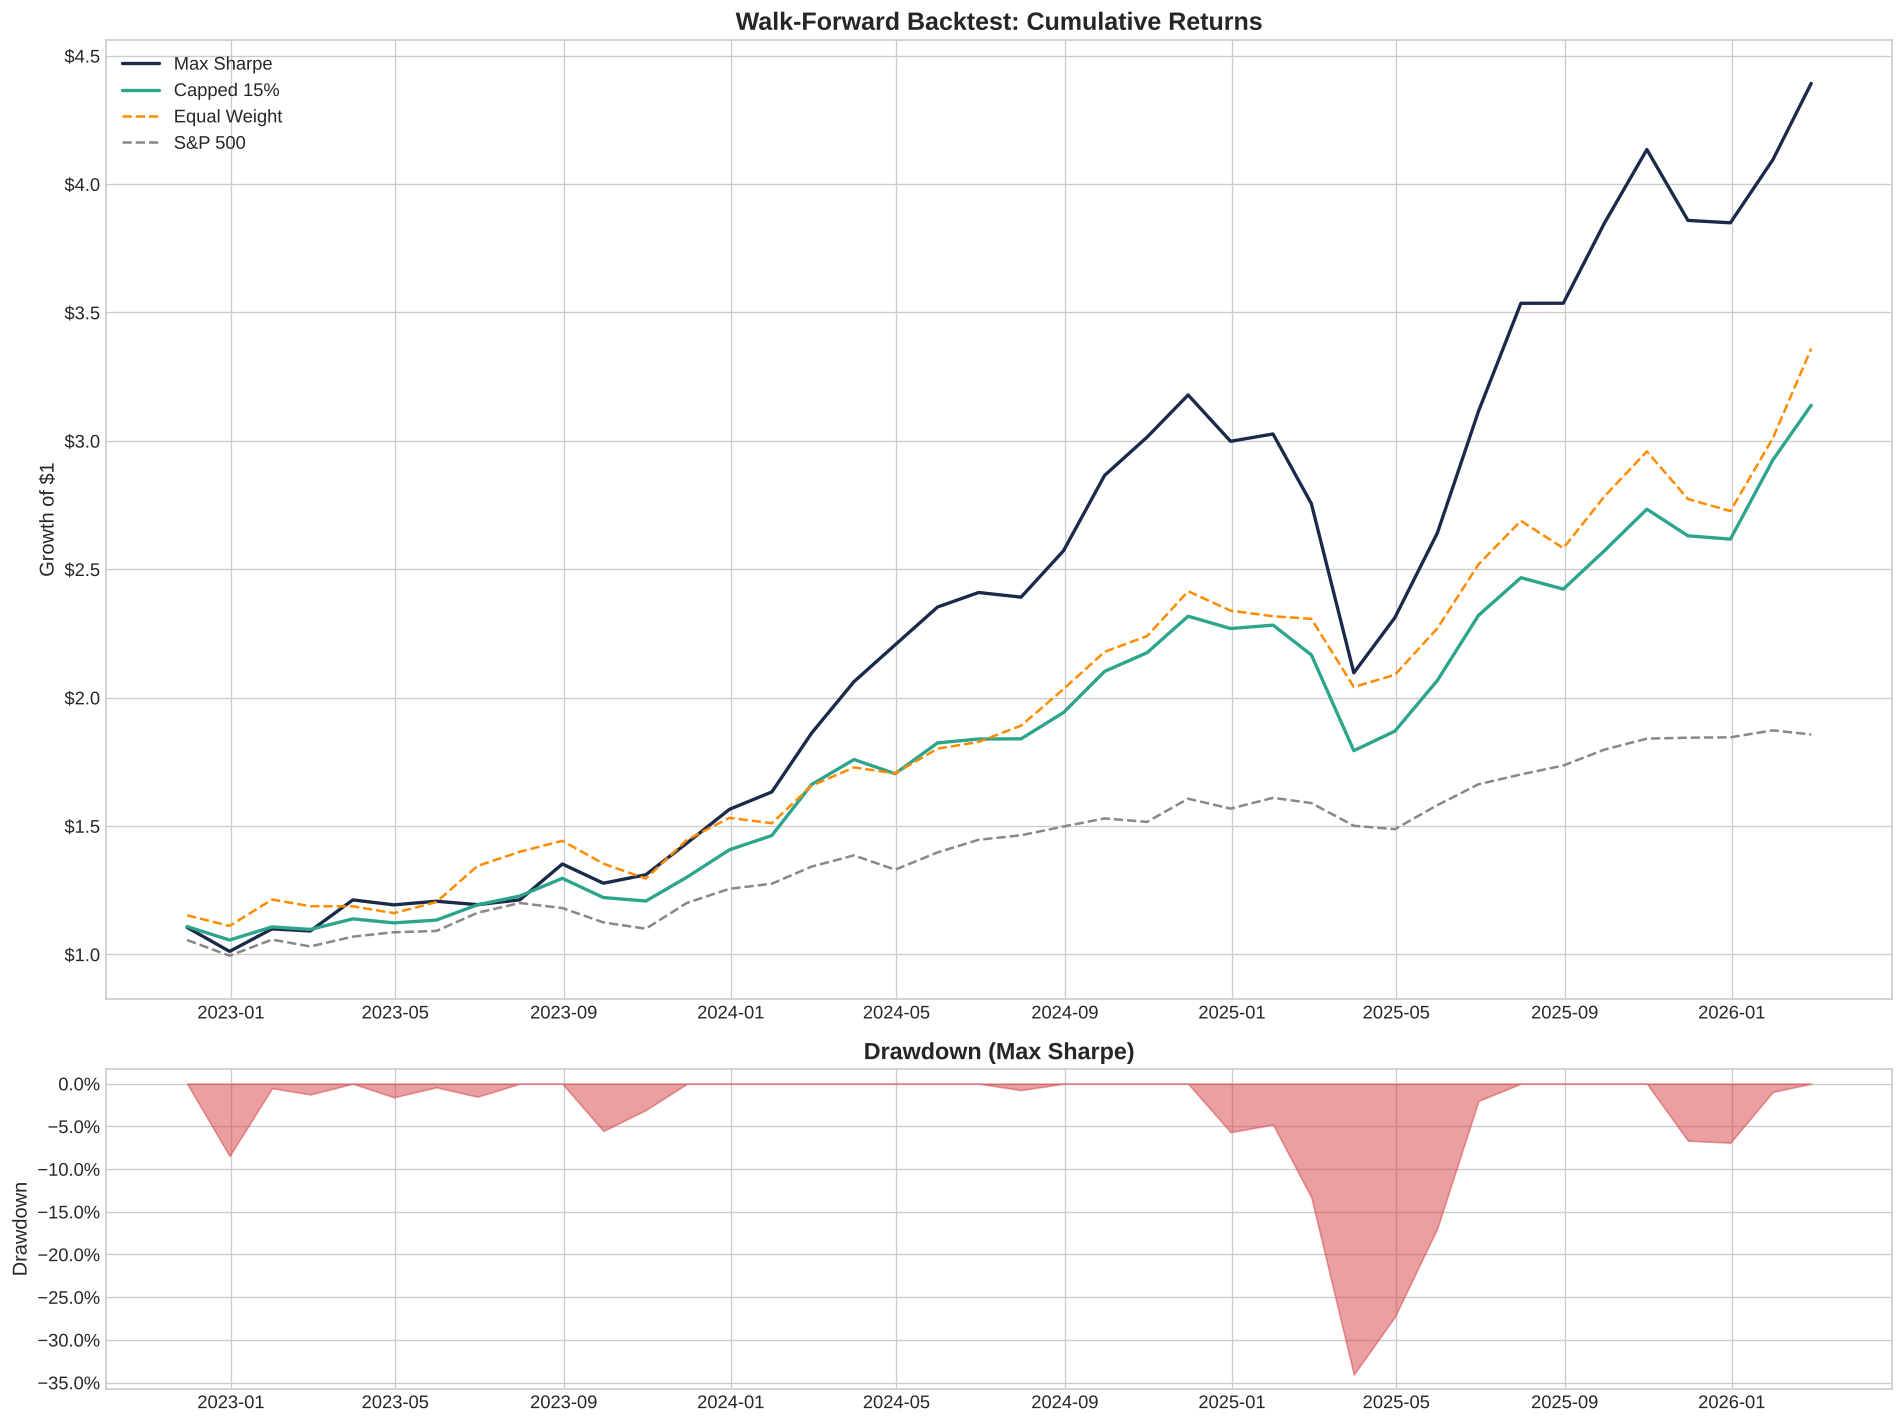

In [19]:
# ── Cumulative Returns & Drawdown ──
fig, axes = plt.subplots(2, 1, figsize=(16, 12), gridspec_kw={'height_ratios': [3, 1]})

cum_ms = (1 + ret_ms).cumprod()
cum_cap = (1 + ret_cap).cumprod()
cum_ew = (1 + ret_ew).cumprod()
cum_b = (1 + ret_bench).cumprod()

axes[0].plot(cum_ms.index, cum_ms, lw=2, color=COLORS['navy'], label='Max Sharpe')
axes[0].plot(cum_cap.index, cum_cap, lw=2, color=COLORS['teal'], label='Capped 15%')
axes[0].plot(cum_ew.index, cum_ew, lw=1.5, color=COLORS['orange'], ls='--', label='Equal Weight')
axes[0].plot(cum_b.index, cum_b, lw=1.5, color=COLORS['gray'], ls='--', label='S&P 500')
axes[0].set_title('Walk-Forward Backtest: Cumulative Returns', fontsize=15, fontweight='bold')
axes[0].set_ylabel('Growth of $1')
axes[0].yaxis.set_major_formatter(mticker.FormatStrFormatter('$%.1f'))
axes[0].legend(fontsize=11)

# Drawdown
dd = (cum_ms - cum_ms.expanding().max()) / cum_ms.expanding().max()
axes[1].fill_between(dd.index, dd, 0, alpha=0.5, color=COLORS['red'])
axes[1].set_title('Drawdown (Max Sharpe)', fontweight='bold')
axes[1].set_ylabel('Drawdown')
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

plt.tight_layout()
plt.show()


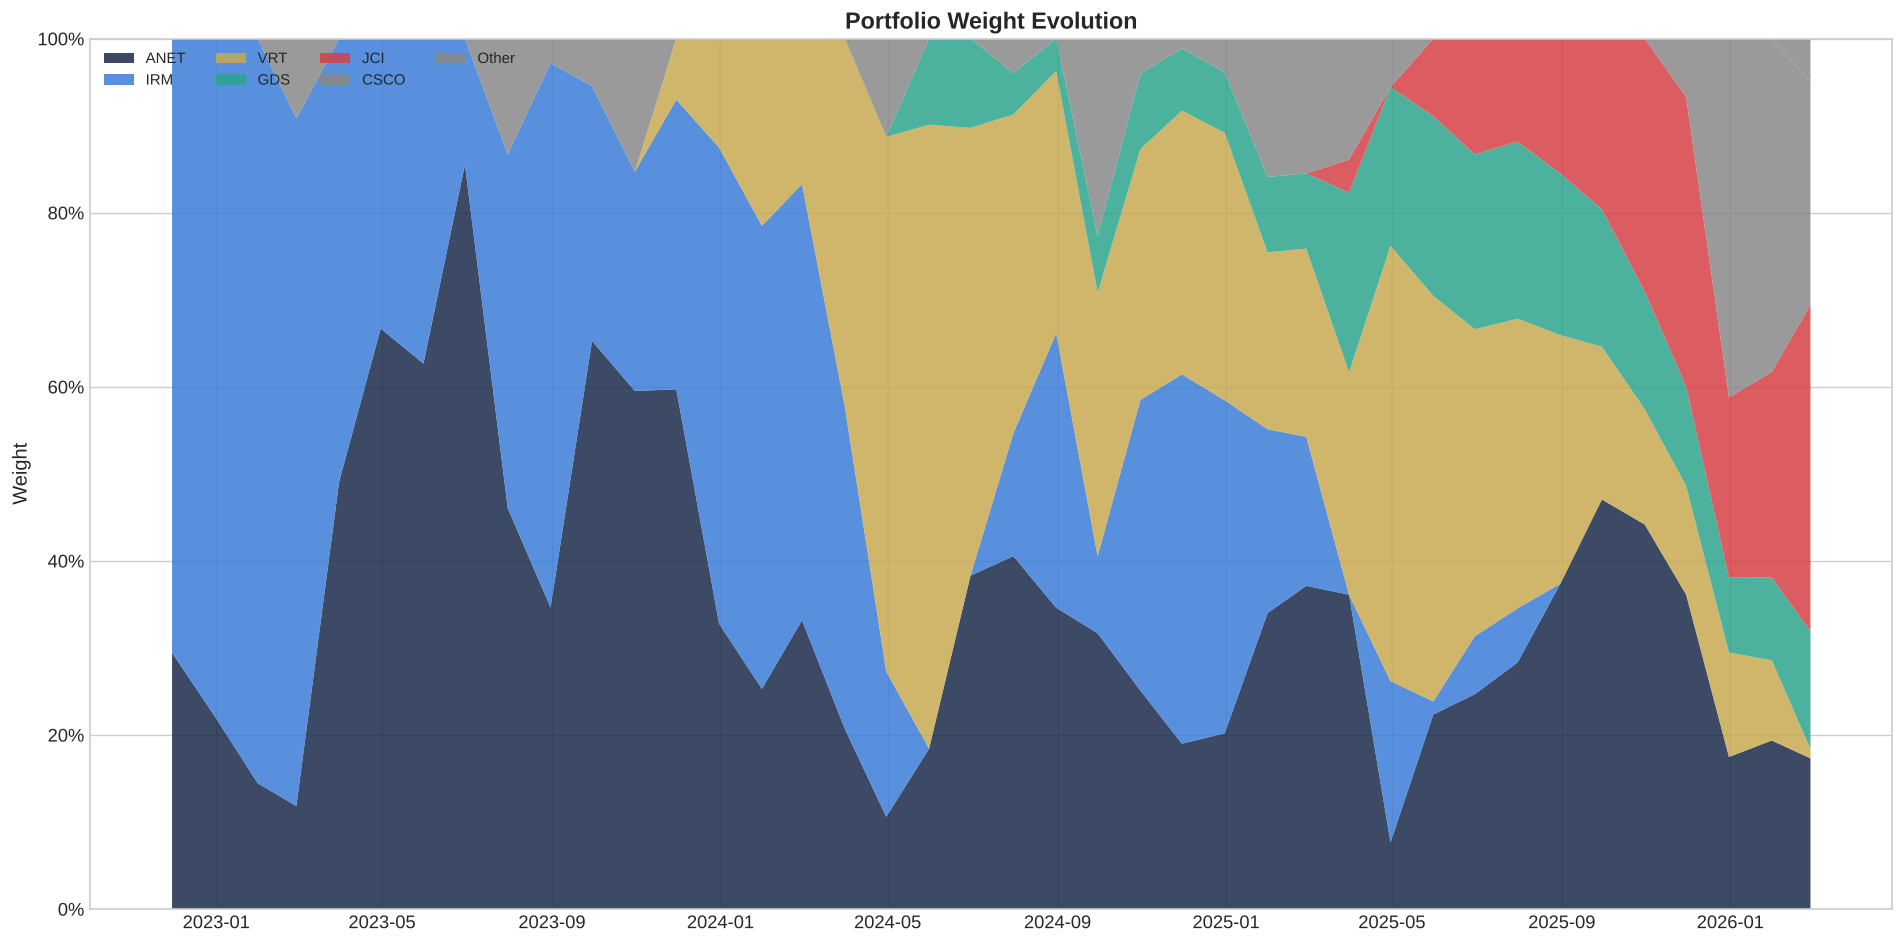

In [20]:
# ── Weight Evolution ──
wt_df = pd.DataFrame(wt_ms, index=ret_ms.index)
top_wt = wt_df.mean().nlargest(6).index.tolist()
plot_wt = wt_df[top_wt].copy()
plot_wt['Other'] = wt_df[[c for c in wt_df.columns if c not in top_wt]].sum(axis=1)

fig, ax = plt.subplots(figsize=(16, 8))
colors_area = [PALETTE[i] for i in range(len(top_wt))] + [COLORS['gray']]
ax.stackplot(plot_wt.index, plot_wt.T, labels=plot_wt.columns, colors=colors_area, alpha=0.85)
ax.set_title('Portfolio Weight Evolution', fontsize=14, fontweight='bold')
ax.set_ylabel('Weight')
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend(loc='upper left', ncol=4, fontsize=9)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()


## 7. Risk analysis

### 7.1 VaR, CVaR and marginal contributions

VaR at level $\alpha$ is the $\alpha$ quantile of the loss distribution. I compute it two ways because they disagree, and the disagreement is the diagnostic.

The historical estimate takes the empirical quantile directly, assuming only that the past sample is representative. Its limitation is that it cannot produce a loss larger than the worst one observed, and here it is computed on 40 monthly backtest returns, so the 99% figure is in effect the worst month observed.

The parametric estimate is $\mu + z_\alpha\sigma$, which assumes normality. Given the excess kurtosis documented in 2.4, it will understate the deep tail. Comparing the two at 95% and 99% quantifies how much the Gaussian assumption costs, and that gap widens with the kurtosis measured earlier.

### Expected Shortfall

$$\mathrm{ES}_\alpha = \mathbb{E}[L \mid L > \mathrm{VaR}_\alpha]$$

ES is the average loss conditional on breaching VaR. It is preferred for a reason beyond convenience: VaR is not subadditive, so the VaR of a combined portfolio can exceed the sum of its parts, which makes it unusable for risk budgeting and perverse as a regulatory constraint. Artzner et al. (1999) set out the coherence axioms VaR fails; ES satisfies them. The Basel framework's move from VaR to ES in the trading book rests on this.

### Marginal contribution to risk

$$\mathrm{MCTR}_i = \frac{\partial \sigma_p}{\partial w_i} = \frac{(\Sigma w)_i}{\sigma_p}, \qquad \mathrm{CTR}_i = w_i \cdot \mathrm{MCTR}_i$$

Because portfolio volatility is homogeneous of degree one in the weights, Euler's theorem gives $\sum_i \mathrm{CTR}_i = \sigma_p$ exactly. Risk decomposes additively even though volatility does not add.

This is the number that reveals concentration that the weight vector hides. A 5% position in a high-volatility name correlated with everything else can contribute 15% of portfolio risk. The weights say the portfolio is diversified; the risk contributions say where the exposure actually is.

### What it produced

At 95% the methods are close: historical VaR of -8.5% a month, Gaussian -9.1%, Student-$t$ -7.7%. That is the expected pattern, since the Gaussian error concentrates further out in the tail. The historical 99% figure of -18.1% is a single month and should not be read as an estimate.

The risk decomposition makes the concentration argument concrete. GDS holds 13.5% of the final weights and contributes 25.7% of the portfolio's risk, nearly double its share, because it is the most volatile name in the book. Johnson Controls at 37.5% of capital carries 36.4% of risk. Between them two names account for 62% of the portfolio's volatility.

In [21]:
# ══════════════════════════════════════════════════════════════
# RISK ANALYSIS
# ══════════════════════════════════════════════════════════════

# Historical VaR & CVaR
print("Historical VaR & CVaR (Monthly, Max Sharpe Portfolio)\n")
for alpha in [0.90, 0.95, 0.99]:
    var = np.percentile(ret_ms, (1 - alpha) * 100)
    cvar = ret_ms[ret_ms <= var].mean()
    print(f"  {alpha:.0%} confidence:  VaR = {var:.2%},  CVaR = {cvar:.2%}")

# Parametric
mu_p, sig_p = ret_ms.mean(), ret_ms.std()
print(f"\nParametric VaR (95%):  Gaussian = {mu_p + norm.ppf(0.05)*sig_p:.2%}")
params_t = t_dist.fit(ret_ms)
print(f"  Student-t (df={params_t[0]:.1f}):     {t_dist.ppf(0.05, *params_t):.2%}")

# ── Marginal Contribution to Risk ──
print("\nMarginal Contribution to Risk (MCTR) — Last Rebalance Weights:\n")
last_w = np.array(list(wt_ms[-1].values()))
Sigma_ann = cov_full.values * 12
port_vol = np.sqrt(last_w @ Sigma_ann @ last_w)
mctr = (Sigma_ann @ last_w) / port_vol
cr = last_w * mctr

print(f"{'Ticker':<8} {'Weight':>8} {'MCTR':>8} {'RiskContrib':>12} {'%Total':>8}")
print("-" * 48)
for i in np.argsort(-cr):
    if last_w[i] > 0.005:
        print(f"{bt_tickers[i]:<8} {last_w[i]:>7.2%} {mctr[i]:>7.2%} {cr[i]:>11.2%} {cr[i]/port_vol:>7.1%}")
print(f"{'TOTAL':<8} {'100%':>7} {'':>8} {port_vol:>11.2%} {'100.0%':>8}")


Historical VaR & CVaR (Monthly, Max Sharpe Portfolio)

  90% confidence:  VaR = -5.78%,  CVaR = -12.01%
  95% confidence:  VaR = -8.49%,  CVaR = -16.44%
  99% confidence:  VaR = -18.08%,  CVaR = -23.91%

Parametric VaR (95%):  Gaussian = -9.09%
  Student-t (df=6.4):     -7.73%

Marginal Contribution to Risk (MCTR) — Last Rebalance Weights:

Ticker     Weight     MCTR  RiskContrib   %Total
------------------------------------------------
JCI       37.52%  22.66%       8.50%   36.4%
GDS       13.53%  44.33%       6.00%   25.7%
CSCO      25.60%  16.08%       4.12%   17.6%
ANET      17.30%  20.34%       3.52%   15.1%
CAT        4.98%  19.58%       0.98%    4.2%
VRT        1.06%  24.22%       0.26%    1.1%
TOTAL       100%               23.37%   100.0%


### 7.2 Tail dependence

Correlation is a statement about the whole joint distribution and says almost nothing about its corners. Two series can have a correlation of 0.3 and still crash together with near certainty, or almost never.

The coefficient of lower tail dependence captures what correlation misses:

$$\lambda_L = \lim_{q \to 0^+} \Pr\left(U_1 \le q \mid U_2 \le q\right)$$

where $U_1, U_2$ are the probability integral transforms of the two series. It is the limiting probability that one asset is in its worst $q$ fraction given that the other is.

The result that makes this worth computing: the Gaussian copula has $\lambda_L = 0$ for every correlation below 1. Under a Gaussian dependence assumption, joint extreme losses are asymptotically independent no matter how strongly correlated the assets are in normal conditions. The Student-$t$ copula, by contrast, has strictly positive tail dependence that increases as degrees of freedom fall.

This is not an academic distinction. It is the specific modelling assumption behind the mispricing of structured credit before 2008, where Gaussian copula models of correlated default assigned negligible probability to the simultaneous-default scenarios that subsequently occurred. Estimating $\lambda_L$ empirically here tests whether this portfolio's diversification survives into the tail or exists only in the middle of the distribution, which is the only place it is not needed.


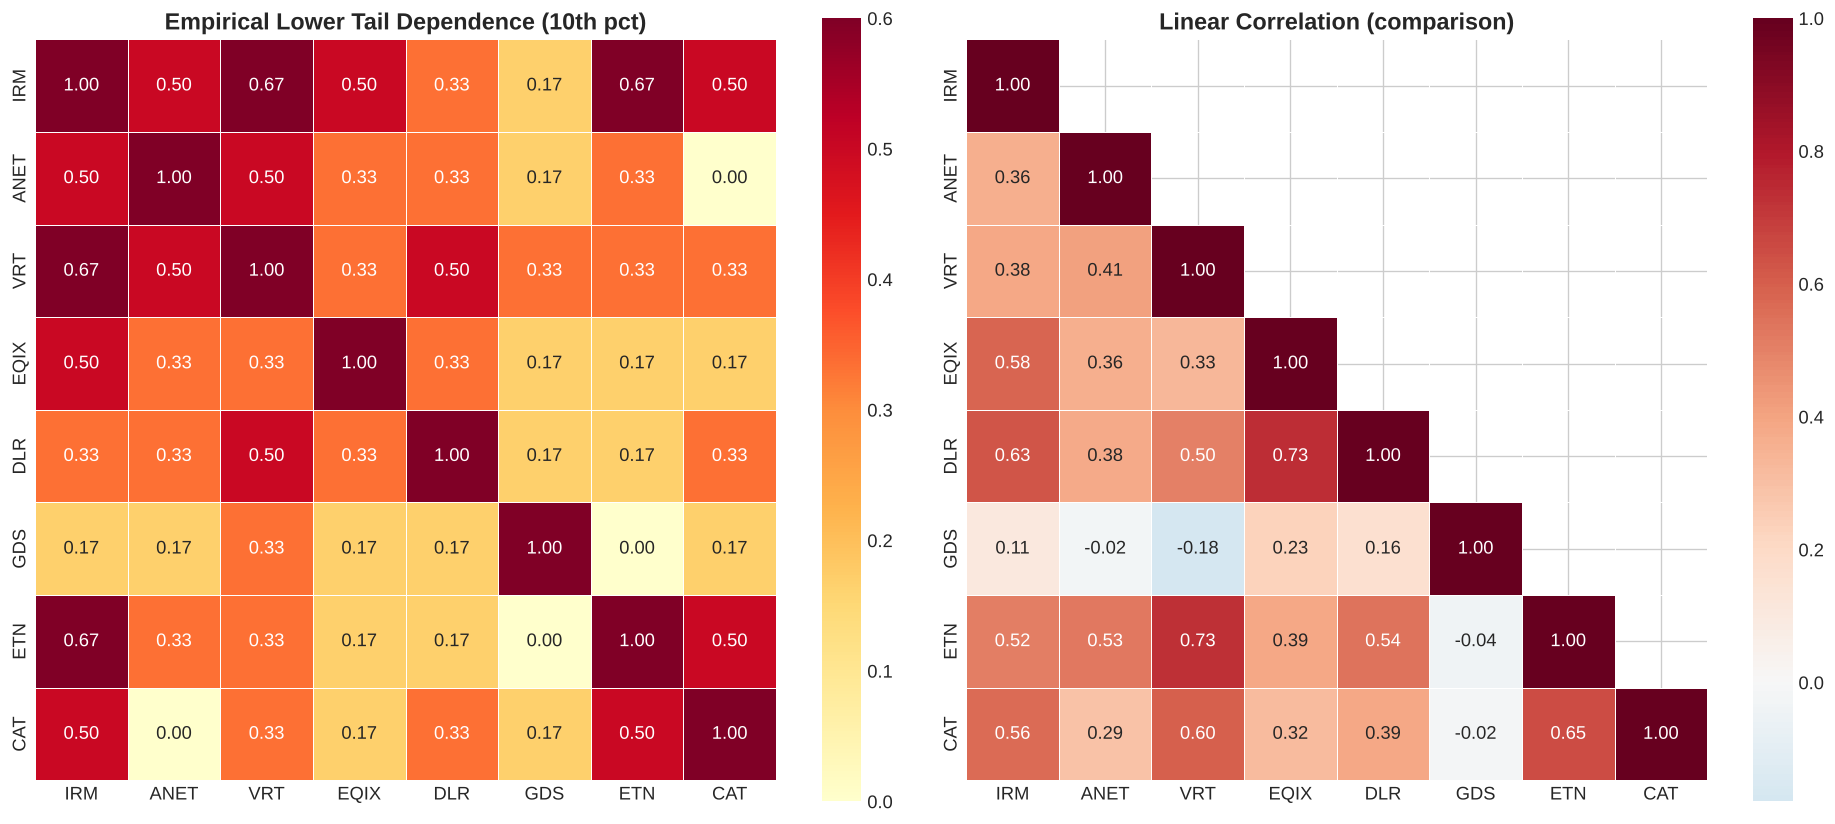

Pairs with low linear correlation but elevated tail dependence indicate
asymmetric co-movement — correlations spike during stress. This means
Gaussian-copula VaR underestimates crisis losses.


In [22]:
# ══════════════════════════════════════════════════════════════
# TAIL DEPENDENCE (EMPIRICAL)
# ══════════════════════════════════════════════════════════════

def tail_dep(u, v, q=0.10):
    """Empirical lower tail dependence: P(V<=q | U<=q)."""
    mask = u <= q
    return (v[mask] <= q).mean() if mask.sum() > 0 else 0

# Probability Integral Transform
uniforms = pd.DataFrame(index=monthly_returns.index)
for t in bt_tickers:
    data = monthly_returns[t].dropna()
    uniforms[t] = rankdata(data) / (len(data) + 1)

top_8 = [t for t in ['IRM', 'ANET', 'VRT', 'EQIX', 'DLR', 'GDS', 'ETN', 'CAT'] if t in uniforms.columns]

td_mtx = pd.DataFrame(np.nan, index=top_8, columns=top_8)
for i, t1 in enumerate(top_8):
    for j, t2 in enumerate(top_8):
        if i <= j:
            c = uniforms[[t1, t2]].dropna()
            if len(c) > 20:
                td = tail_dep(c[t1].values, c[t2].values, q=0.10)
                td_mtx.loc[t1, t2] = td
                td_mtx.loc[t2, t1] = td

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.heatmap(td_mtx.astype(float), annot=True, fmt='.2f', cmap='YlOrRd',
            vmin=0, vmax=0.6, ax=axes[0], linewidths=0.5, square=True)
axes[0].set_title('Empirical Lower Tail Dependence (10th pct)', fontweight='bold')

corr_sub = monthly_returns[top_8].corr()
mask2 = np.triu(np.ones_like(corr_sub, dtype=bool), k=1)
sns.heatmap(corr_sub, mask=mask2, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, ax=axes[1], linewidths=0.5, square=True)
axes[1].set_title('Linear Correlation (comparison)', fontweight='bold')

plt.tight_layout()
plt.show()

print("Pairs with low linear correlation but elevated tail dependence indicate")
print("asymmetric co-movement — correlations spike during stress. This means")
print("Gaussian-copula VaR underestimates crisis losses.")


## 8. Monte Carlo projection

Ten thousand paths over fifteen years, drawing from the historical covariance structure with forward-looking expected returns.

### Read this section with more scepticism than any other

The mechanics are standard and the implementation is fine. The problem is the inputs, and it is severe enough that the output should be treated as an illustration of dispersion rather than a forecast.

**The horizon exceeds the sample.** Fifteen years are projected from a little over five years of history, and that window contains a liquidity expansion, a rate shock and an AI repricing, but no crash and no prolonged bear market in this theme. The covariance matrix is estimated from a regime, not from the population.

**The expected returns do not survive extrapolation.** Several names in this universe realised annualised returns well above 50% over the sample. Compounding any such figure for fifteen years produces terminal wealth multiples that imply market capitalisations exceeding plausible bounds on the addressable market. A thematic growth rate estimated during the steepest part of an adoption curve is not a long-run expected return, and treating it as one is the single largest error available in this kind of analysis.

**Volatility drag is where the dispersion comes from.** If arithmetic returns are drawn each period, median terminal wealth grows at roughly $\mu - \sigma^2/2$ rather than $\mu$. For a portfolio at 30% volatility that is a gap of about 4.5 percentage points a year, which over fifteen years separates the mean outcome from the median one by a very large factor. The mean of the terminal distribution is accordingly a poor summary, and the median and the quantiles should be read instead.

**No regime switching, no fat tails, no mean reversion.** Returns are drawn i.i.d. from a fixed distribution, so the simulation cannot produce a sustained drawdown of the kind the sample itself contains.

A defensible version of this exercise would use expected returns anchored to something other than the realised sample, such as a factor-implied or analyst-consensus estimate, and would draw from a regime-switching or bootstrap-based process rather than a fixed multivariate normal. What is below should be read as a sensitivity analysis on compounding and dispersion, not as a projection of where this portfolio ends up.

### The output makes the point by itself

The simulation reports a median fifteen-year CAGR of 30.9%, turning $10,000 into $566,000, a tenth-percentile CAGR of 21.4%, and a probability of ending the fifteen years with a loss of exactly 0.00%. A model that assigns no chance of loss over fifteen years to a concentrated single-theme equity portfolio is describing its inputs, not the world. Every one of those figures should be read as a consequence of the assumptions listed above.

In [23]:
# ══════════════════════════════════════════════════════════════
# MONTE CARLO SIMULATION
# ══════════════════════════════════════════════════════════════

def monte_carlo(weights, mu_ann, cov_monthly, n_sims=10000, n_years=15, initial=10000):
    """Simulate portfolio wealth paths via correlated GBM draws."""
    n_months = n_years * 12
    mu_m = mu_ann / 12
    L = np.linalg.cholesky(cov_monthly)
    
    paths = np.zeros((n_sims, n_months + 1))
    paths[:, 0] = initial
    rets = np.zeros((n_sims, n_months))
    
    for s in range(n_sims):
        for m in range(n_months):
            z = np.random.standard_normal(len(weights))
            r = mu_m + L @ z
            pr = weights @ r
            rets[s, m] = pr
            paths[s, m+1] = paths[s, m] * (1 + pr)
    
    return paths, rets

# Use last optimization weights and historical parameters
sim_w = np.array(list(wt_ms[-1].values()))
sim_mu = monthly_returns[bt_tickers].mean().values * 12
sim_cov = monthly_returns[bt_tickers].cov().values

print("Running Monte Carlo simulation (10,000 paths x 15 years)...")
np.random.seed(42)
paths, sim_rets = monte_carlo(sim_w, sim_mu, sim_cov)
print("Done.\n")

# Quick summary
end_bal = paths[:, -1]
cagrs = (end_bal / paths[:, 0]) ** (1/15) - 1
mdd = np.array([((p - np.maximum.accumulate(p)) / np.maximum.accumulate(p)).min() for p in paths])

print(f"{'Percentile':<12} {'End Balance':>14} {'CAGR':>10} {'Max DD':>10}")
print("-" * 50)
for pct in [10, 25, 50, 75, 90]:
    print(f"  {pct}th{'':>6} ${np.percentile(end_bal, pct):>12,.0f} "
          f"{np.percentile(cagrs, pct):>9.2%} {np.percentile(mdd, pct):>9.2%}")


Running Monte Carlo simulation (10,000 paths x 15 years)...


Done.

Percentile      End Balance       CAGR     Max DD
--------------------------------------------------
  10th       $     184,133    21.43%   -40.67%
  25th       $     315,950    25.89%   -34.56%
  50th       $     566,200    30.88%   -28.87%
  75th       $   1,036,593    36.26%   -24.31%
  90th       $   1,794,610    41.34%   -20.99%


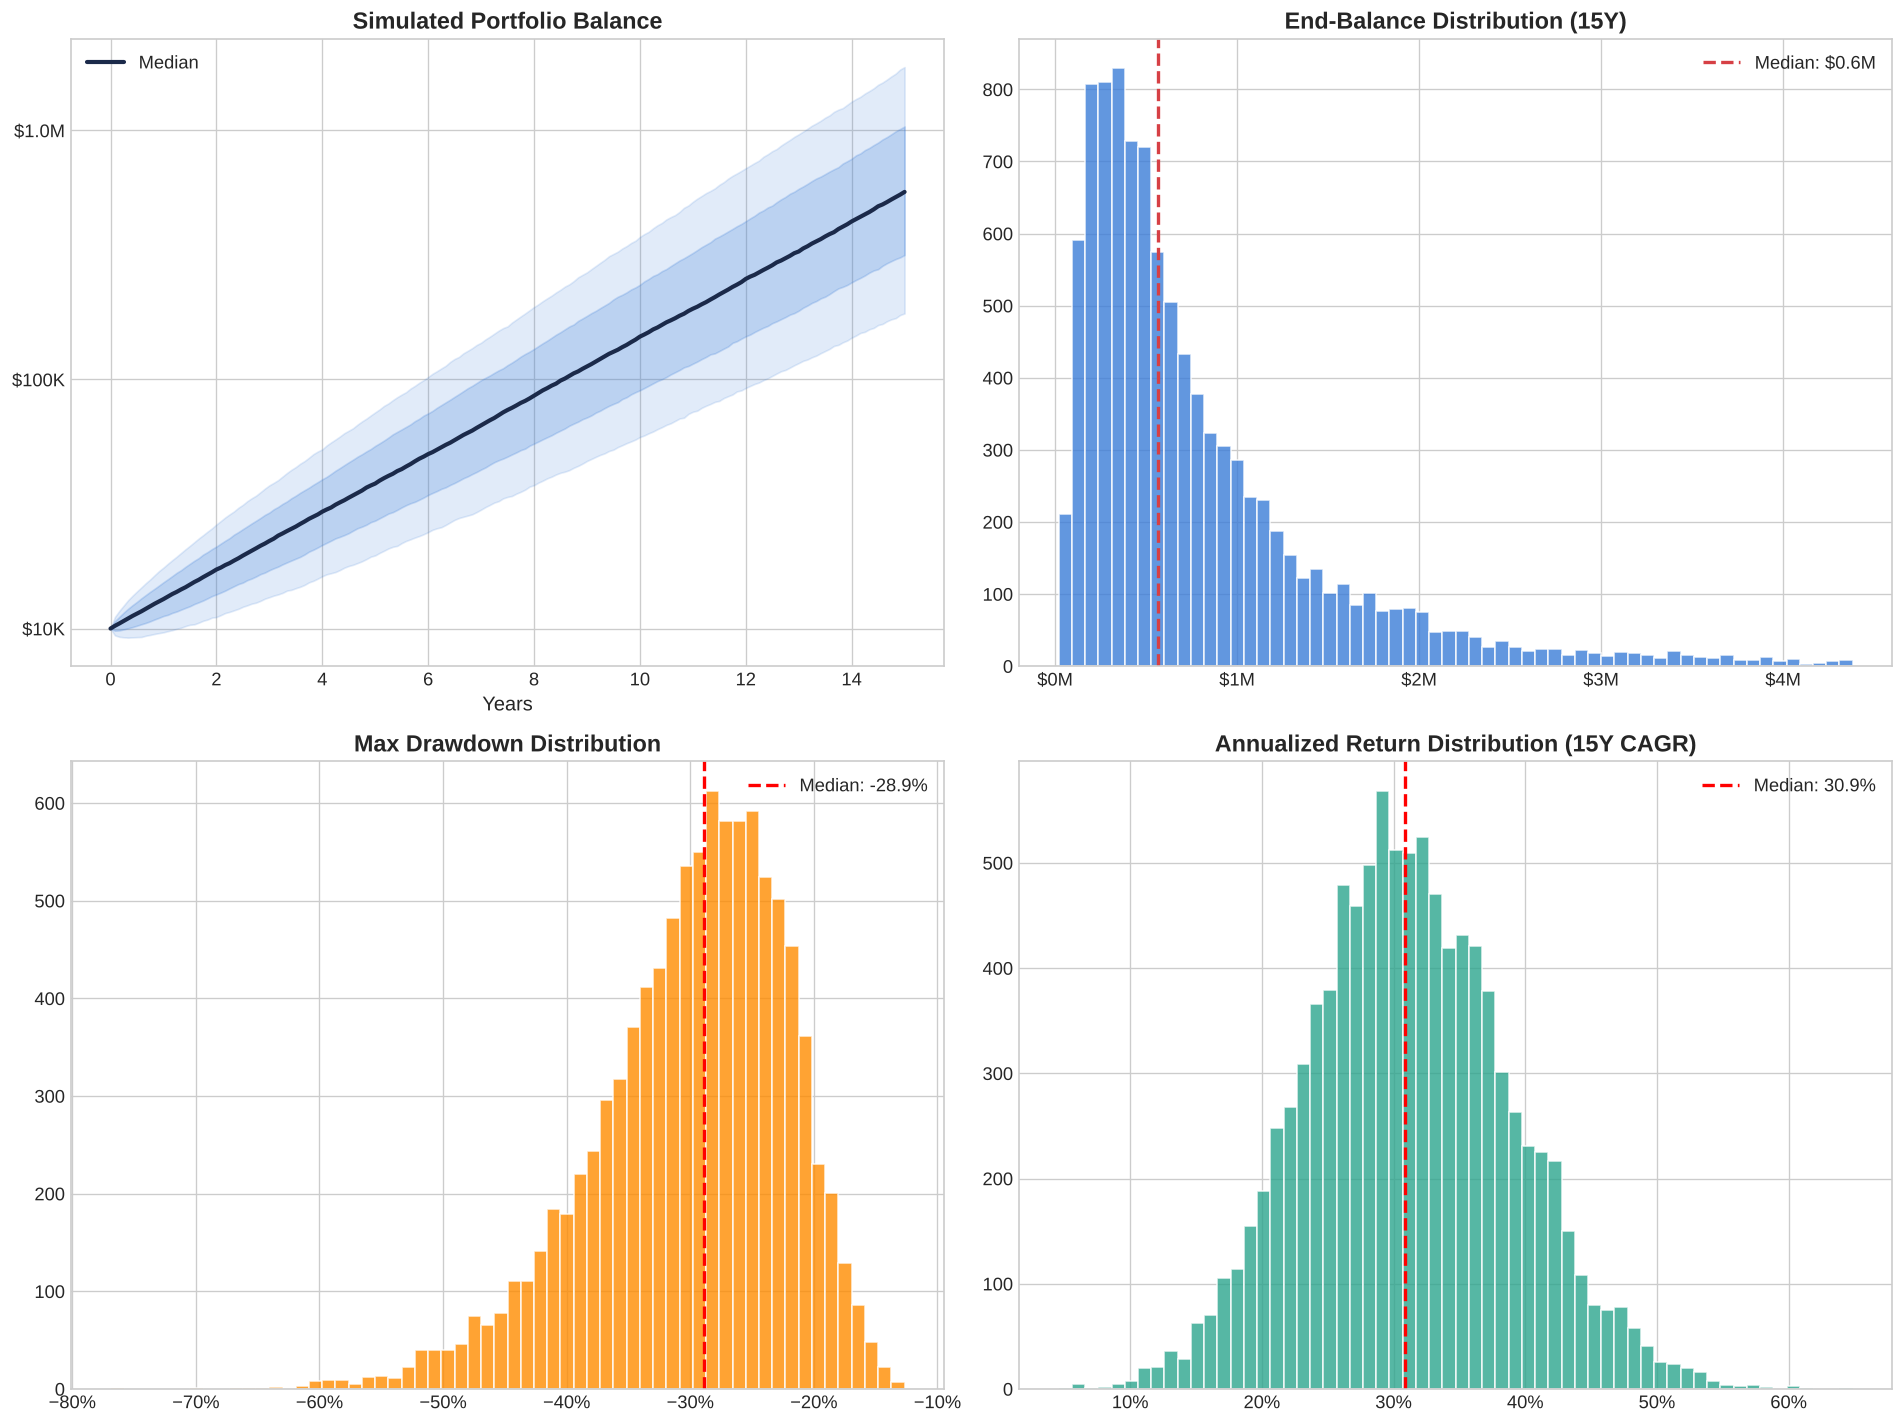

In [24]:
# ── Monte Carlo Visualization ──
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Fan chart
ax = axes[0, 0]
months = np.arange(paths.shape[1]) / 12
for p_lo, p_hi in [(10, 90), (25, 75)]:
    alpha = 0.15 + (90 - p_hi) * 0.005
    ax.fill_between(months, np.percentile(paths, p_lo, axis=0),
                    np.percentile(paths, p_hi, axis=0), alpha=alpha, color=COLORS['blue'])
ax.plot(months, np.percentile(paths, 50, axis=0), lw=2.5, color=COLORS['navy'], label='Median')
ax.set_title('Simulated Portfolio Balance', fontweight='bold')
ax.set_xlabel('Years')
ax.set_yscale('log')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M' if x>=1e6 else f'${x/1e3:.0f}K'))
ax.legend()

# 2. End-balance histogram
ax = axes[0, 1]
clip = np.percentile(end_bal, 99)
ax.hist(end_bal[end_bal <= clip], bins=60, color=COLORS['blue'], edgecolor='white', alpha=0.8)
ax.axvline(np.median(end_bal), color=COLORS['red'], ls='--', lw=2,
           label=f'Median: ${np.median(end_bal)/1e6:.1f}M')
ax.set_title('End-Balance Distribution (15Y)', fontweight='bold')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.0f}M'))
ax.legend()

# 3. Max drawdown histogram
ax = axes[1, 0]
ax.hist(mdd, bins=60, color=COLORS['orange'], edgecolor='white', alpha=0.8)
ax.axvline(np.median(mdd), color='red', ls='--', lw=2, label=f'Median: {np.median(mdd):.1%}')
ax.set_title('Max Drawdown Distribution', fontweight='bold')
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend()

# 4. CAGR histogram
ax = axes[1, 1]
ax.hist(cagrs, bins=60, color=COLORS['teal'], edgecolor='white', alpha=0.8)
ax.axvline(np.median(cagrs), color='red', ls='--', lw=2, label=f'Median: {np.median(cagrs):.1%}')
ax.set_title('Annualized Return Distribution (15Y CAGR)', fontweight='bold')
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend()

plt.tight_layout()
plt.show()


### 8.1 Return and loss probabilities

The probability tables translate the simulated distribution into statements about outcomes. They inherit every limitation in section 8 and should carry the same discount.

The quantity worth attention is the gap between the mean and the median terminal value. That gap is the volatility drag made concrete, and it is the reason a portfolio can have an attractive expected return and still deliver a disappointing result to most of the people who hold it.


In [25]:
# ── Return probability table ──
horizons = [1, 3, 5, 10, 15]
thresholds = [0.0, 0.025, 0.05, 0.075, 0.10, 0.125]

print("Annual Return Probability (P(CAGR >= threshold)):\n")
header = f"{'Threshold':<12}" + "".join(f"{h}Y{'':>7}" for h in horizons)
print(header)
print("-" * 55)

for thresh in thresholds:
    row = f">= {thresh:.1%}{'':>4}"
    for h in horizons:
        m = h * 12
        if m < paths.shape[1]:
            cagr_h = (paths[:, m] / paths[:, 0]) ** (1/h) - 1
            row += f"{(cagr_h >= thresh).mean():>8.1%}"
        else:
            row += f"{'N/A':>8}"
    print(row)

# ── Loss probability table ──
print("\n\nLoss Probability (at any point during horizon):\n")
print(f"{'Loss >=':>10} {'Within Period':>14} {'At End (15Y)':>12}")
print("-" * 40)
for thresh in [0.025, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]:
    within = (paths.min(axis=1) < 10000 * (1 - thresh)).mean()
    at_end = (paths[:, -1] < 10000 * (1 - thresh)).mean()
    print(f"  {thresh:>6.1%}     {within:>12.2%}   {at_end:>10.2%}")


Annual Return Probability (P(CAGR >= threshold)):

Threshold   1Y       3Y       5Y       10Y       15Y       
-------------------------------------------------------
>= 0.0%       87.5%   97.5%   99.5%  100.0%  100.0%
>= 2.5%       85.2%   96.3%   99.1%  100.0%  100.0%
>= 5.0%       83.0%   94.5%   98.2%   99.9%  100.0%
>= 7.5%       80.5%   92.6%   97.0%   99.7%   99.9%
>= 10.0%       77.7%   90.2%   95.1%   99.2%   99.9%
>= 12.5%       74.8%   87.1%   92.5%   98.0%   99.4%


Loss Probability (at any point during horizon):

   Loss >=  Within Period At End (15Y)
----------------------------------------
    2.5%           48.46%        0.00%
    5.0%           38.74%        0.00%
   10.0%           24.17%        0.00%
   15.0%           13.98%        0.00%
   20.0%            8.34%        0.00%
   25.0%            4.41%        0.00%
   30.0%            2.42%        0.00%
   35.0%            1.14%        0.00%
   40.0%            0.48%        0.00%


## 9. Summary

The exhibits below consolidate the allocation, the risk decomposition, the backtest and the projection. What I take from the exercise, stated as findings:

**Optimisation added nothing.** In the walk-forward, equal weighting beat both optimised portfolios on Sharpe ratio and drawdown, with no help from transaction costs and with the selection bias of section 4.3 working in the optimiser's favour.

**The theme is concentrated in fewer bets than it looks.** Within-cluster optimisation collapses three of four clusters to a single name, and two names carry 62% of the final portfolio's risk.

**Factors explain less than expected, and not in the expected direction.** The data centre REITs load as growth assets, not value, and for most names the five factors explain under half the variance.

**The headline figures are biased upward**, by universe selection on full-sample Sharpe ratio, by the absence of transaction costs in section 6, by reporting the best of several strategies without correction, and by a sample that starts after the 2020 crash. The companion notebook removes the first three. The Monte Carlo projection should not be quoted at all.

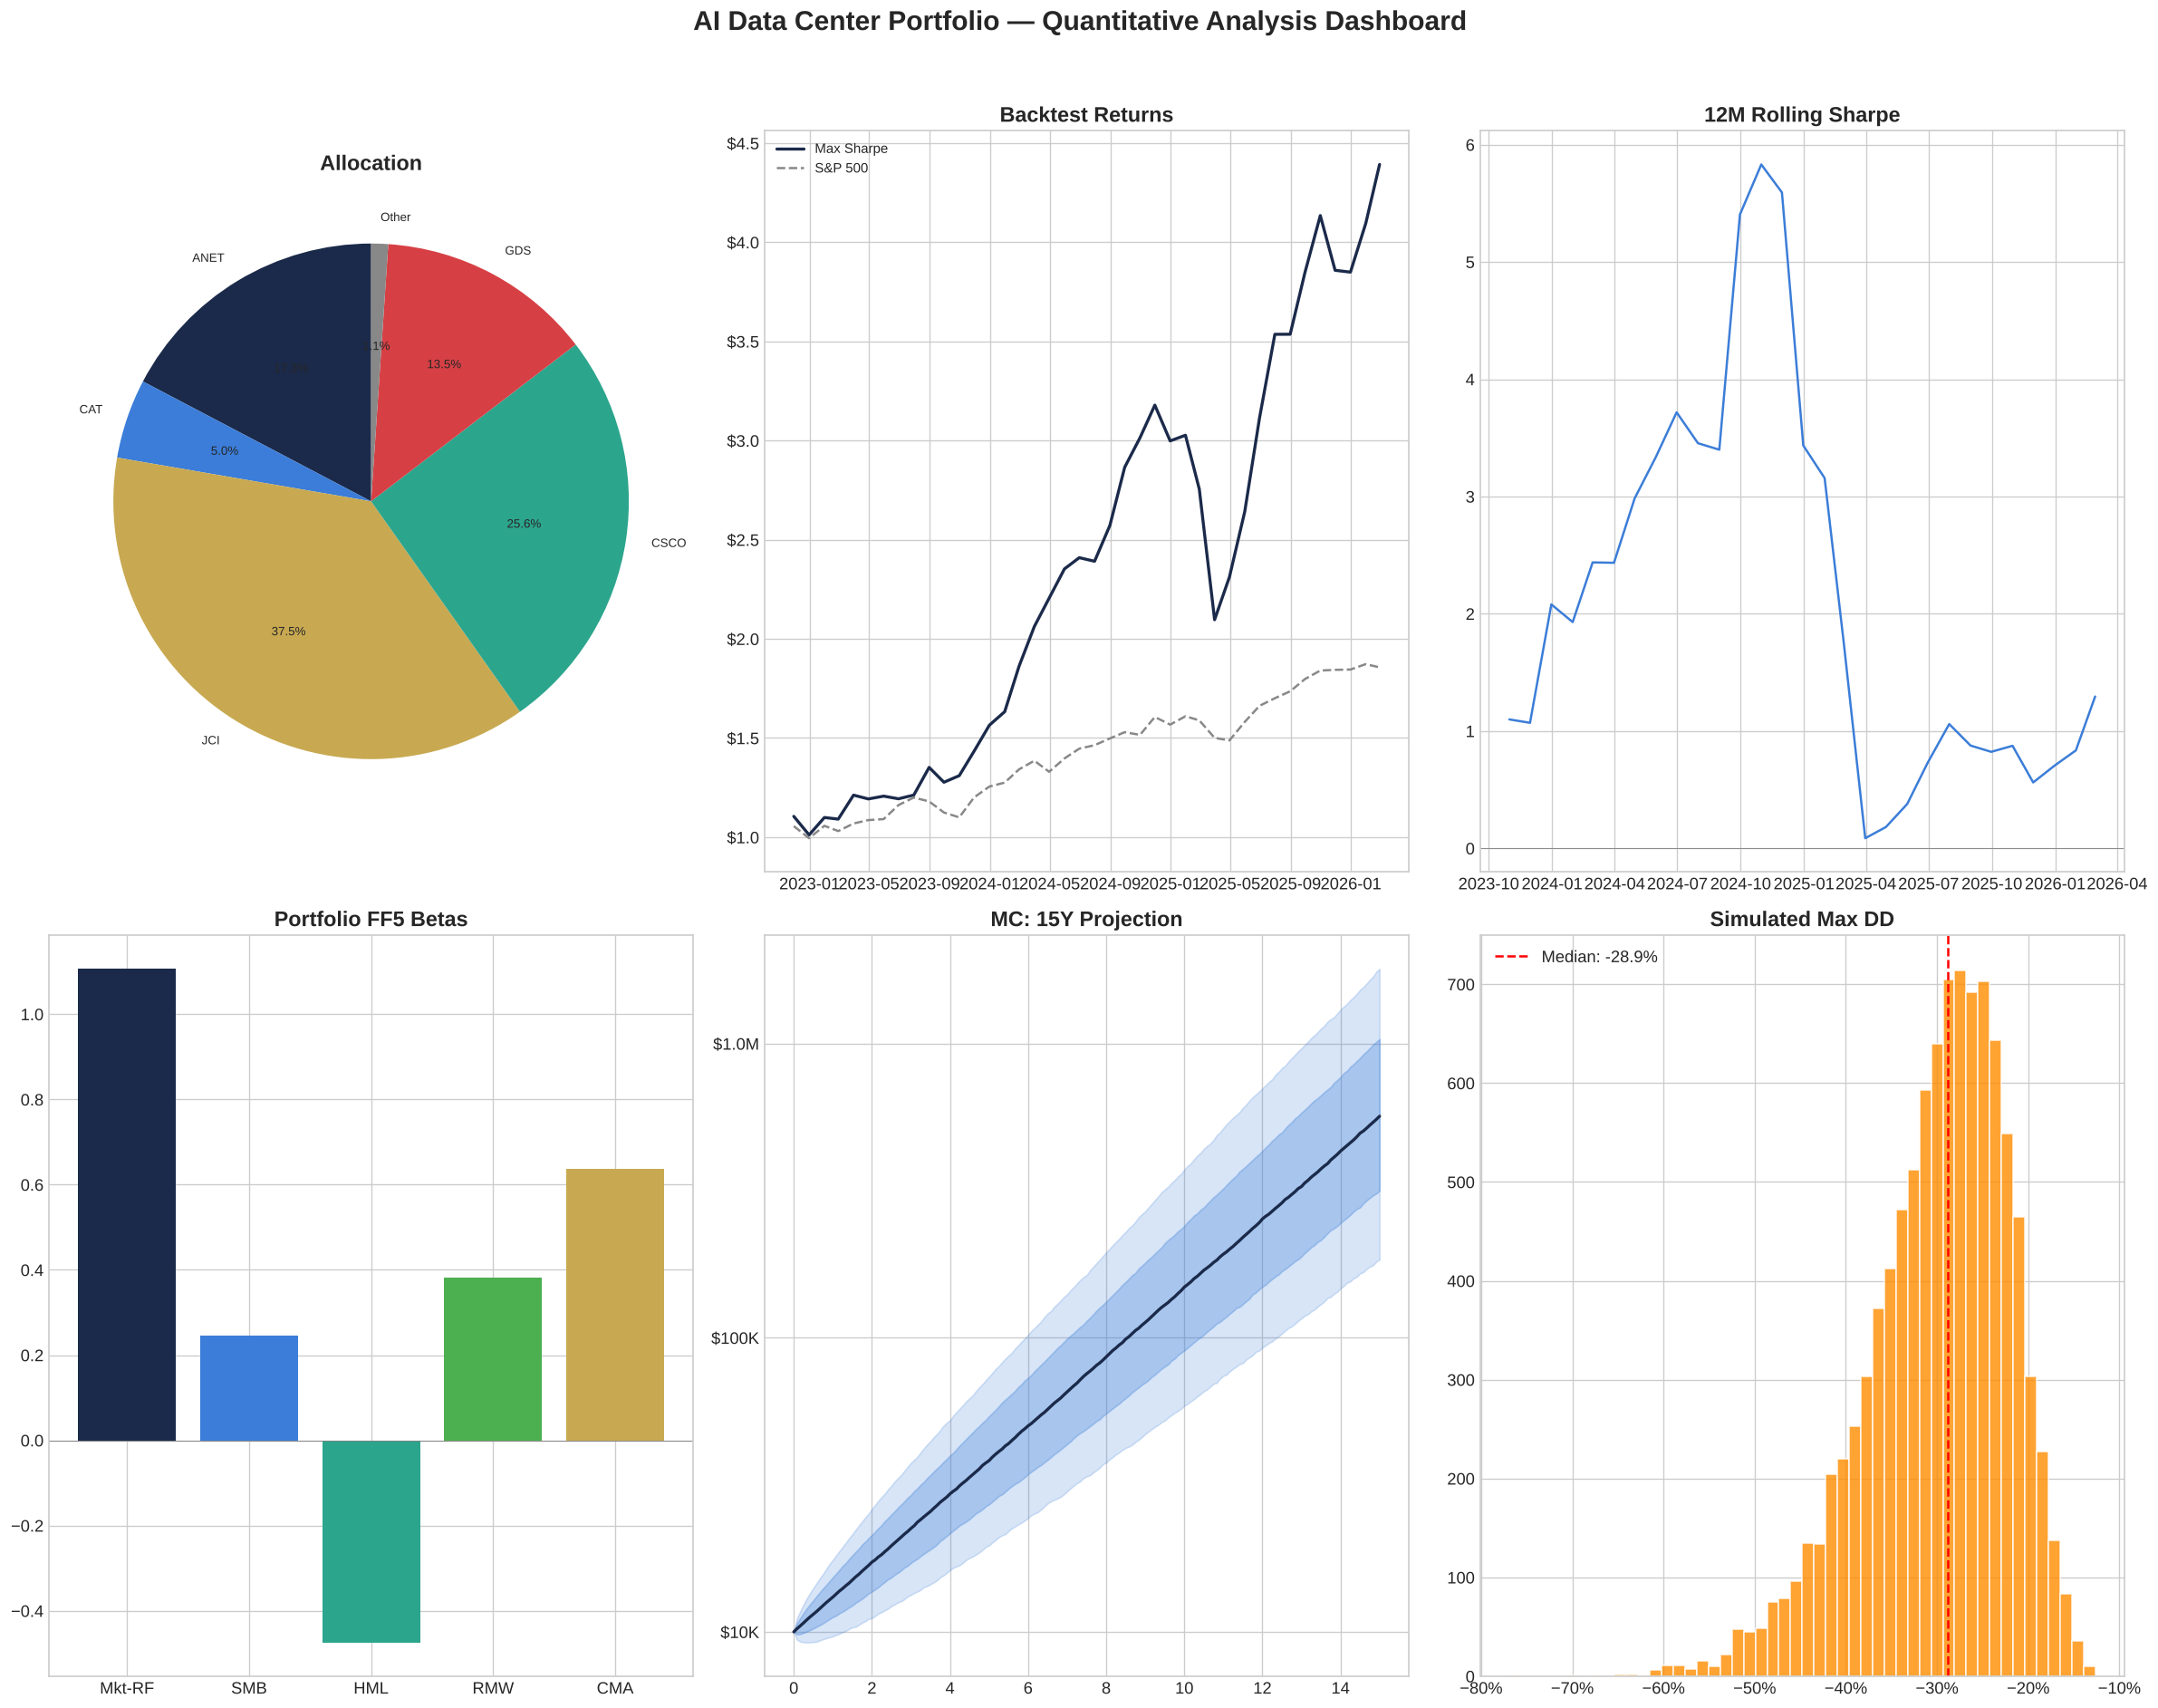


  ANALYSIS COMPLETE
  Backtest CAGR:           55.88%
  Backtest Sharpe:         1.61
  Backtest Sortino:        1.89
  Backtest Max DD:         -34.05%
  MC Median CAGR (15Y):    30.88%
  MC Median End Value:     $566,200
  MC P(Loss at 15Y):       0.00%


In [26]:
# ══════════════════════════════════════════════════════════════
# COMPREHENSIVE DASHBOARD
# ══════════════════════════════════════════════════════════════

fig = plt.figure(figsize=(20, 16))
fig.suptitle('AI Data Center Portfolio — Quantitative Analysis Dashboard',
             fontsize=18, fontweight='bold', y=0.98)

# 1. Allocation
ax1 = fig.add_subplot(2, 3, 1)
labels = [t for t, w in zip(bt_tickers, sim_w) if w > 0.02]
sizes = [w for w in sim_w if w > 0.02]
other = sum(w for w in sim_w if w <= 0.02)
if other > 0: labels.append('Other'); sizes.append(other)
ax1.pie(sizes, labels=labels, colors=[PALETTE[i%len(PALETTE)] for i in range(len(labels))],
        autopct='%1.1f%%', startangle=90, textprops={'fontsize': 8})
ax1.set_title('Allocation', fontweight='bold')

# 2. Cumulative
ax2 = fig.add_subplot(2, 3, 2)
ax2.plot(cum_ms.index, cum_ms, lw=2, color=COLORS['navy'], label='Max Sharpe')
ax2.plot(cum_b.index, cum_b, lw=1.5, color=COLORS['gray'], ls='--', label='S&P 500')
ax2.set_title('Backtest Returns', fontweight='bold')
ax2.legend(fontsize=9)
ax2.yaxis.set_major_formatter(mticker.FormatStrFormatter('$%.1f'))

# 3. Rolling Sharpe
ax3 = fig.add_subplot(2, 3, 3)
rs = (ret_ms.rolling(12).mean() - RF_MONTHLY) / ret_ms.rolling(12).std() * np.sqrt(12)
ax3.plot(rs.index, rs, lw=1.5, color=COLORS['blue'])
ax3.axhline(0, color='gray', lw=0.5)
ax3.set_title('12M Rolling Sharpe', fontweight='bold')

# 4. Factor exposures
ax4 = fig.add_subplot(2, 3, 4)
if ff_results:
    port_betas = {}
    for f in factors:
        pb = sum(ff_results.get(t, {}).get(f'beta_{f}', 0) * w
                for t, w in zip(bt_tickers, sim_w) if t in ff_results)
        port_betas[f] = pb
    ax4.bar(port_betas.keys(), port_betas.values(),
            color=[COLORS['navy'], COLORS['blue'], COLORS['teal'], COLORS['green'], COLORS['gold']])
    ax4.axhline(0, color='gray', lw=0.5)
    ax4.set_title('Portfolio FF5 Betas', fontweight='bold')

# 5. MC fan
ax5 = fig.add_subplot(2, 3, 5)
m = np.arange(paths.shape[1]) / 12
ax5.fill_between(m, np.percentile(paths, 10, axis=0), np.percentile(paths, 90, axis=0),
                 alpha=0.2, color=COLORS['blue'])
ax5.fill_between(m, np.percentile(paths, 25, axis=0), np.percentile(paths, 75, axis=0),
                 alpha=0.3, color=COLORS['blue'])
ax5.plot(m, np.percentile(paths, 50, axis=0), lw=2, color=COLORS['navy'])
ax5.set_title('MC: 15Y Projection', fontweight='bold')
ax5.set_yscale('log')
ax5.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M' if x>=1e6 else f'${x/1e3:.0f}K'))

# 6. Drawdown hist
ax6 = fig.add_subplot(2, 3, 6)
ax6.hist(mdd, bins=50, color=COLORS['orange'], edgecolor='white', alpha=0.8)
ax6.axvline(np.median(mdd), color='red', ls='--', label=f'Median: {np.median(mdd):.1%}')
ax6.set_title('Simulated Max DD', fontweight='bold')
ax6.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax6.legend()

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("\n" + "="*70)
print("  ANALYSIS COMPLETE")
print("="*70)
print(f"  Backtest CAGR:           {metrics.loc['Max Sharpe', 'CAGR']:.2%}")
print(f"  Backtest Sharpe:         {metrics.loc['Max Sharpe', 'Sharpe']:.2f}")
print(f"  Backtest Sortino:        {metrics.loc['Max Sharpe', 'Sortino']:.2f}")
print(f"  Backtest Max DD:         {metrics.loc['Max Sharpe', 'Max DD']:.2%}")
print(f"  MC Median CAGR (15Y):    {np.median(cagrs):.2%}")
print(f"  MC Median End Value:     ${np.median(end_bal):,.0f}")
print(f"  MC P(Loss at 15Y):       {(end_bal < 10000).mean():.2%}")
print("="*70)


---

## What comes next

The immediate priority is not a new model but two corrections identified above: a market-capitalisation prior for Black-Litterman, and views written relative to that prior rather than as absolute returns. The posterior covariance bug has been fixed in place, and the companion notebook selects its universe on training data only and is where the defensible performance figures live.

Beyond that:

**Regime switching.** A hidden Markov model on the return series would allow the allocation to differ between high and low volatility states instead of being optimised for an average of both. This is being built as a separate project.

**Shrinkage estimators.** Ledoit-Wolf for the covariance matrix, which given the 171 parameters estimated from 64 observations in section 2.2 should matter more than any change to the objective function.

**Transaction costs and turnover penalties.** The monthly maximum Sharpe strategy is unlikely to survive realistic costs, and a turnover penalty inside the objective is the standard remedy.

**A better expected return input.** Everything downstream of section 4 is limited by the quality of $\mu$, and historical means over a five-year thematic window are close to the weakest available estimate.